# Committor of a 2D Toytis Staple Run (Brownian or Langevin)

Set up for the **Langevin Z run** `sim_istarz_2603` (γ = 2, dt 0.002). The run records positions only (`v_ord = False`), so the CVs are (y, x, Δy/dt, Δx/dt) (finite-difference velocities) and there is no shooting reference (it needs the true velocity of a frame) and no exact committor. Compare with the MD committor of `toy2d_md-lgv.ipynb` (`MD_COMMITTOR_NPZ`) if there is one; section 9 (new trajectories) needs recorded velocities and stops with a message.

Fits the committor (`CommittorNE`, NPNEq) to the paths of a toytis staple (i\*) run on a 2D potential, and checks it against references. Generic: the run's dynamics (Brownian or Langevin, friction, time step, temperature), interfaces, recorded velocities and potential are read from its `logging.log`; nothing in the code is specific to one potential.

**Path data** (`tis_data.prepare_data`, notes §3–§9): every path is cut at its first frame past its ensemble's interface M, its mirrored piece (the part before the last M crossing, read backwards; velocities negated) is added with `REVERSED`, and every piece carries its path's rejection weight. A and B ends are treated as traps for the metrics.

**CVs** (`CVS = 'auto'`): the positions (y, x) for Brownian runs; for Langevin runs also the recorded velocities (v_y, v_x) if the run saved them (`v_ord = True`), or finite-difference velocities with `FD_VELOCITY`.

**Fit lag** (`FIT_LAG = 'auto'`): 1 for Brownian runs; for Langevin Δ ≈ 0.05/(γ dt) frames with the stopped-window lag-Δ update (notes §10.1), since over one step the energy hardly changes.

**References:**
- *Exact* (Brownian runs): the overdamped committor on a grid (`toy2d.exact_committor_brownian`), absorption every step as in the run. It also tests the data: put into the stopped Z_q of the data, the exact committor should pass at every lag.
- *Shooting* (both dynamics; Langevin needs recorded velocities): the committor of `N_SHOOT_POINTS` random frames from `N_SHOTS` new trajectories each, with the run's integrator.
- The model-free MD reference of `toy2d_md.ipynb` can also be compared (`MD_COMMITTOR_NPZ`).

All figures are shown and saved to `FIG_DIR` (`figures_by_potential/<potential>/<brownian|langevin>_g<gamma>/staple/` for the `sim_istar_*` runs, `staple_test/` for the `test_*` runs, `staple_<run>/` for others); the fit's plots go to `FIG_DIR/<fit tag>/seed<s>/it<N>_<plot>.png`.

**Weights:** `FIT_WEIGHTED = (True, False)` fits the same paths with the MC weights and with every path once, and section 7b compares the two. **Stopped Z_q** (`STOPPED_ENDS`): windows passing a piece end at a turn use q at that end; A/B ends get a trap longer than any piece plus the longest Z_q lag.

## 1. Imports

In [1]:
import argparse
import os
import sys
import time
import types

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import seed_runs
import tis_data
import toy2d

## 2. Settings

| Name | Default | Meaning |
|---|---|---|
| `TIS_DIR` | | the staple run |
| `POTENTIAL`, `POT_KWARGS` | `None` | `None`: rebuilt from the run's log; else `module:Class` and its arguments |
| `LAMBDA_A`, `LAMBDA_B` | `None` | states; `None`: first and last interface |
| `PATHS_PER_ENSEMBLE`, `PATH_SEED` | `None`, 0 | random subset of accepted paths per ensemble (`None`: all) |
| `REVERSED`, `WEIGHTS`, `MAX_LENGTH` | True, `rejections`, `None` | mirrored pieces, MC weights read with the paths, piece-length limit (truncation) |
| `FIT_WEIGHTED` | (True, False) | fits to run on the same paths, one per entry: `True` the MC weights of `WEIGHTS`, `False` every path once (weight 1), or a tistools scheme by name (`'rejections'`, `'staple'`, `'none'`; a scheme other than `WEIGHTS` is read again: same frames, other weights). Section 7b compares them |
| `STOPPED_ENDS` | True | stopped Z_q: a window passing a piece end that is not in A/B (a turn) uses q at that end; A/B ends get a trap longer than any piece plus the longest Z_q lag |
| `CVS`, `FD_VELOCITY` | `auto`, False | fit CVs (names from y, x, vy, vx, dy, dx); finite-difference velocities |
| `FIT_LAG` | `auto` | fit lag in frames |
| `FIT_SEEDS`, `WARMUP_ITER`, `WARMUP_ENVELOPE` | [0], 1000, 1 | seeds; warm-up with a wide envelope |
| `MAX_ITER`, `CHUNK`, `ENVELOPE`, `FIT_GAMMA`, `NY` | 10000, 2500, 0.01, 0.1, 6 | main fit; plots every chunk |
| `N_SHOOT_POINTS`, `N_SHOTS` | 300, 200 | shooting reference (0: off) |
| `MD_COMMITTOR_NPZ` | `None` | `committor.npz` of `toy2d_md.ipynb` for the same potential and dynamics (optional) |

Rough cost: about 0.4 s per iteration per 20M frames; the stopped-Z_q metrics need about 250 bytes per frame on the GPU, so use `PATHS_PER_ENSEMBLE` to stay well below ~25M frames on an 8 GB GPU.

In [10]:
TIS_DIR = f'{toy2d.TOYTIS}/simulations/sim_istarz_lgv_g2_vord'
POTENTIAL, POT_KWARGS = 'sjoelbak_angle:RectangularGridWithAngledBarrierPotential', dict(Lx=0.3, angle=45)   # the log of this run does not record the potential
LAMBDA_A, LAMBDA_B = None, None
PATHS_PER_ENSEMBLE, PATH_SEED = 1000, 0
REVERSED, WEIGHTS, MAX_LENGTH = True, 'rejections', None
FIT_WEIGHTED = (True, False)        # fits on the same paths: True the MC weights of WEIGHTS, False every path once, or a scheme name ('staple')
STOPPED_ENDS = True                 # stopped Z_q: windows past a turn end use q at that end
CVS, FD_VELOCITY = 'auto', False
FIT_LAG = 1
FIT_SEEDS = [0]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1000000
MAX_ITER, CHUNK = 20000, 2500
ENVELOPE, FIT_GAMMA, NY = 0.01, 0.1, 6
N_SHOOT_POINTS, N_SHOTS = 300, 200
MD_COMMITTOR_NPZ = None
MIN_COUNT = 20                      # frames a bin needs to be shown

RUN = os.path.basename(TIS_DIR.rstrip('/'))
run = toy2d.read_full_settings(TIS_DIR)
BROWNIAN = bool(run.get('high_friction', False))
DT, KT, GAMMA, MASS = run['dt'], run['temperature'], run['friction'], run.get('mass', 1.0)
V_ORD = bool(run.get('v_ord', False))
pot = toy2d.potential_from_settings(run, POTENTIAL, POT_KWARGS)
print(f'{RUN}: {"Brownian" if BROWNIAN else "Langevin"}, dt {DT}, kT {KT}, gamma {GAMMA}, mass {MASS}, '
      f'velocities recorded: {V_ORD}, {run["max_cycles"]} cycles requested')
print('interfaces', run['interfaces'])
print('potential', repr(pot))

if CVS == 'auto':
    CVS = ('y', 'x') if BROWNIAN else (('y', 'x', 'vy', 'vx') if V_ORD else ('y', 'x', 'dy', 'dx'))
FD_VELOCITY = FD_VELOCITY or any(c in CVS for c in ('dy', 'dx'))
if FIT_LAG == 'auto':
    FIT_LAG = 1 if BROWNIAN else max(1, int(round(0.05 / (GAMMA * DT))))
def scheme_of(w):
    """Weight scheme of a FIT_WEIGHTED entry: True = WEIGHTS (read with the paths), False = 'none', else its name."""
    return WEIGHTS if w is True else 'none' if w is False else w

def label_of(w):
    return 'without weights' if scheme_of(w) == 'none' else f'{scheme_of(w)} weights'

def tag_for(w):
    """Fit tag: the data, the weights used in the fit, the CVs and the fit settings."""
    return (f'{"rev" if REVERSED else "fwd"}_{scheme_of(w)}_p{PATHS_PER_ENSEMBLE}_s{PATH_SEED}'
            + (f'_len{MAX_LENGTH}' if MAX_LENGTH else '') + f'_{"-".join(CVS)}_lag{FIT_LAG}'
            + f'_env{ENVELOPE:g}_g{FIT_GAMMA:g}_it{MAX_ITER}' + ('_stopped' if STOPPED_ENDS else ''))
assert len({scheme_of(w) for w in FIT_WEIGHTED}) == len(FIT_WEIGHTED), 'two FIT_WEIGHTED entries give the same weights'
fit_tag = tag_for(FIT_WEIGHTED[0])
POT_DIRS = {'CurvedChannelDoubleWell': '2d_curved_channel', 'RectangularGridWithAngledBarrierPotential': '2d_zpot', 'CosWellWalls': '1d_cos_well'}
STAPLE_DIRS = {'sim_istar_cc_br': 'staple', 'sim_istar_cc_lgv': 'staple', 'test_cc_br': 'staple_test', 'test_cc_lgv': 'staple_test',
               'sim_istarz_2603': 'sim_istarz_2603'}
FIG_DIR = (f'{REPO}/examples/figures_by_potential/{POT_DIRS.get(type(pot).__name__, "_unsorted")}/'
           f'{"brownian" if BROWNIAN else "langevin"}_g{GAMMA:g}/{STAPLE_DIRS.get(RUN, "staple_" + RUN)}')
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name, fig=None):
    (fig or plt.gcf()).savefig(f'{FIG_DIR}/{name}.png', dpi=110, bbox_inches='tight')

print('CVs', CVS, '| fit lag', FIT_LAG, '| figures', FIG_DIR, '| fit tags', [tag_for(w) for w in FIT_WEIGHTED])
# === SETTINGS END ===

sim_istarz_lgv_g2_vord: Langevin, dt 0.002, kT 0.05, gamma 2.0, mass 1, velocities recorded: True, 50000 cycles requested
interfaces [0.05, 0.13, 0.21, 0.29, 0.37, 0.45, 0.53, 0.61, 0.69, 0.77, 0.85]
potential <potentials.sjoelbak_angle.RectangularGridWithAngledBarrierPotential object at 0x7f604eee6fd0>
CVs ('y', 'x', 'vy', 'vx') | fit lag 1 | figures /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord | fit tags ['rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped', 'rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped']


## 3. Load the Paths

`tis_data.prepare_data` with the settings above; `data.X_all` holds every column of `order.txt` after the time (y, x, and v_y, v_x if recorded), plus Δy, Δx per frame with `FD_VELOCITY`.

In [11]:
parser = argparse.ArgumentParser()
tis_data.add_data_arguments(parser)
argv = [TIS_DIR, '--weights', WEIGHTS]
if LAMBDA_A is not None:
    argv += ['--lambda-a', str(LAMBDA_A)]
if LAMBDA_B is not None:
    argv += ['--lambda-b', str(LAMBDA_B)]
if PATHS_PER_ENSEMBLE is not None:
    argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE), '--seed', str(PATH_SEED)]
if REVERSED:
    argv += ['--reversed']
if MAX_LENGTH is not None:
    argv += ['--max-length', str(MAX_LENGTH)]
if FD_VELOCITY:
    argv += ['--fd-velocity']
args = parser.parse_args(argv)
data = tis_data.prepare_data(args)
LAMBDA_A, LAMBDA_B = args.lambda_a, args.lambda_b

cols = {'y': data.X_all[:, 0], 'x': data.X_all[:, 1]}
if V_ORD:
    cols.update(vy=data.X_all[:, 2], vx=data.X_all[:, 3])
if FD_VELOCITY:
    cols.update(dy=data.X_all[:, -2] / DT, dx=data.X_all[:, -1] / DT)      # per-frame change / dt
Y, X = cols['y'], cols['x']
W = data.path_weights
_weights = {WEIGHTS: W, 'none': np.ones_like(W)}

def weights_for(w):
    """Per-frame weights of a FIT_WEIGHTED entry. A scheme other than WEIGHTS is read again with the same
    settings: the same frames, other path weights."""
    s = scheme_of(w)
    if s not in _weights:
        k = argv.index('--weights')
        other = tis_data.prepare_data(parser.parse_args(argv[:k + 1] + [s] + argv[k + 2:]))
        assert np.array_equal(other.i_traj, data.i_traj), f'{s}: different frames'
        _weights[s] = other.path_weights
        del other
    return _weights[s]
A, B = data.boundary0, data.boundary1
b = A | B
free = ~b
n_pieces, n_paths = len(np.unique(data.i_traj)), len(np.unique(data.group_traj))
print(f'{len(Y):,} frames in {n_pieces} pieces from {n_paths} paths; {A.sum()} frames in A, {B.sum()} in B')

Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/sim_istarz_lgv_g2_vord/logging.log: [0.05, 0.13, 0.21, 0.29, 0.37, 0.45, 0.53, 0.61, 0.69, 0.77, 0.85]
State A: order <= 0.05, state B: order >= 0.85
Note: --seed is ignored; paths are thinned in a fixed pattern (--thin, --paths-per-ensemble), not drawn at random
Found 11 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/sim_istarz_lgv_g2_vord
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/sim_istarz_lgv_g2_vord/001: loaded 1905 pieces, 213881 frames, total weight 2750, cut at M = 0.05
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/sim_istarz_lgv_g2_vord/002: loaded 2000 pieces, 1072893 frames, total weight 3866, cut at M = 0.13
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/sim_istarz_lgv_g2_vord/003: loaded 2000 pieces, 1163912 frames, total weight 3898, cut at M = 0.21
  /home/staff7/fbsskr/Notebooks/Students/elias

## 4. The Data

- The weighted density of frames on the potential, with the interfaces (it is the path-sampling density, not the equilibrium one).
- Piece lengths and the number of pieces and their total weight per ensemble.
- A few pieces of every ensemble on the potential (forward pieces solid, mirrored dashed).
- Langevin with recorded velocities: their distribution (not Maxwellian in general: the paths are selected).

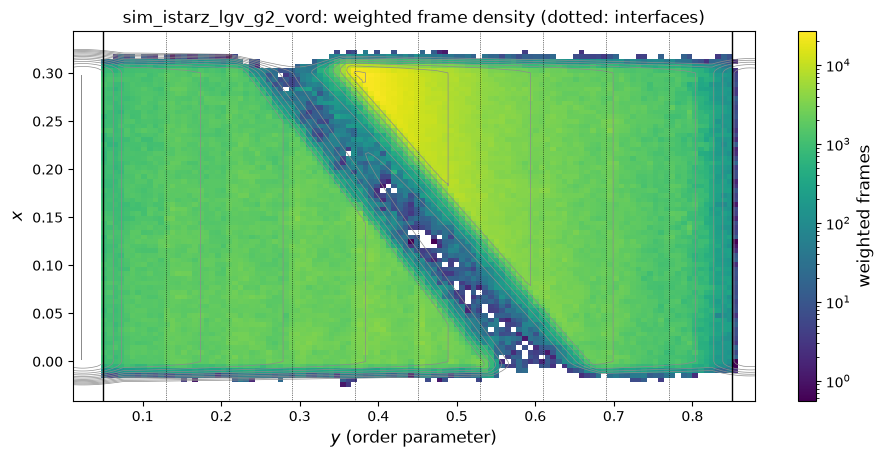

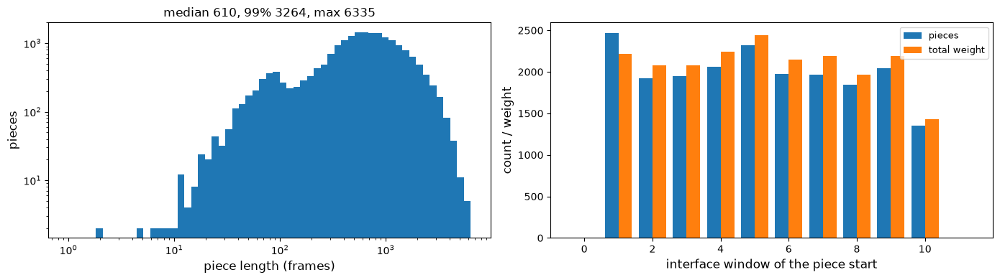

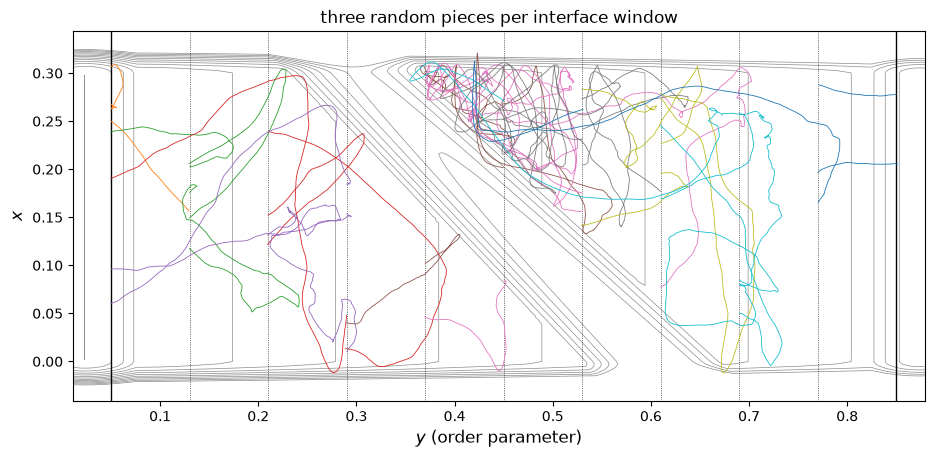

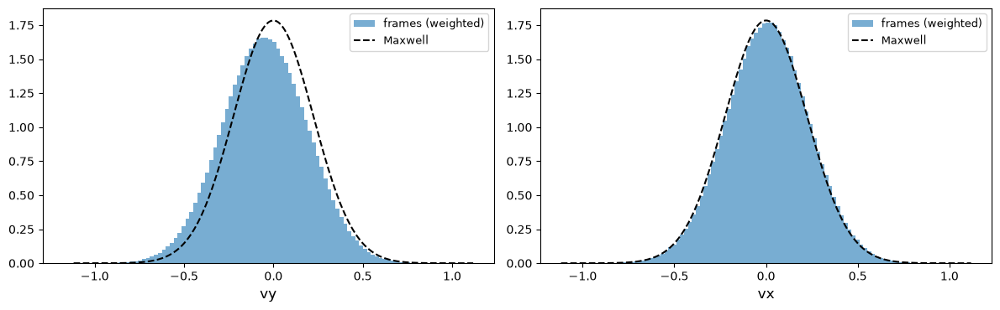

In [12]:
y_lo, y_hi = np.percentile(Y, [0.1, 99.9])
x_lo, x_hi = np.percentile(X, [0.1, 99.9])
pad_y, pad_x = 0.05 * (y_hi - y_lo), 0.1 * (x_hi - x_lo)
Y_RANGE, X_RANGE = (y_lo - pad_y, y_hi + pad_y), (x_lo - pad_x, x_hi + pad_x)
gy, gx = np.linspace(*Y_RANGE, 241), np.linspace(*X_RANGE, 161)
V = toy2d.potential_grid(pot, gy, gx)
V_kT = (V - V.min()) / KT
LEVELS = np.arange(0, 12.5, 1.0)
CONTOURS = (gy, gx, V_kT, LEVELS)
INTFS = run['interfaces']

def draw_potential(ax, intfs=True):
    ax.contour(gy, gx, V_kT.T, levels=LEVELS, colors='0.55', linewidths=0.5)
    if intfs:
        for lam in INTFS:
            ax.axvline(lam, color='k', lw=0.5, ls=':')
        for lam in (LAMBDA_A, LAMBDA_B):
            ax.axvline(lam, color='k', lw=1)
    ax.set(xlim=Y_RANGE, ylim=X_RANGE, xlabel='$y$ (order parameter)', ylabel='$x$')

ey, ex = np.linspace(*Y_RANGE, 121), np.linspace(*X_RANGE, 81)
Hw = np.histogram2d(Y, X, [ey, ex], weights=W)[0]
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.pcolormesh(ey, ex, np.where(Hw > 0, Hw, np.nan).T, norm='log', cmap='viridis')
draw_potential(ax)
fig.colorbar(im, ax=ax, label='weighted frames')
ax.set_title(f'{RUN}: weighted frame density (dotted: interfaces)')
save_fig('data_density')
plt.show()

ends = np.r_[np.flatnonzero(np.diff(data.i_traj) != 0), len(Y) - 1]
starts = np.r_[0, ends[:-1] + 1]
lengths = ends - starts + 1
piece_lam0 = Y[starts]
ens_of_piece = np.digitize(piece_lam0, INTFS)                 # rough ensemble label: interface window of the start
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax1.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces',
        title=f'median {np.median(lengths):.0f}, 99% {np.percentile(lengths, 99):.0f}, max {lengths.max()}')
piece_w = W[starts]
cnt = np.bincount(ens_of_piece, minlength=len(INTFS) + 1)
wsum = np.bincount(ens_of_piece, weights=piece_w, minlength=len(INTFS) + 1)
ax2.bar(np.arange(len(cnt)) - 0.2, cnt, 0.4, label='pieces')
ax2.bar(np.arange(len(cnt)) + 0.2, wsum, 0.4, label='total weight')
ax2.set(xlabel='interface window of the piece start', ylabel='count / weight')
ax2.legend()
fig.tight_layout()
save_fig('data_pieces')
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.8))
draw_potential(ax)
rng = np.random.default_rng(0)
for k in np.unique(ens_of_piece):
    sel = np.flatnonzero(ens_of_piece == k)
    for i in rng.choice(sel, size=min(3, sel.size), replace=False):
        s0, s1 = starts[i], ends[i] + 1
        ax.plot(Y[s0:s1], X[s0:s1], lw=0.6, color=f'C{k % 10}')
ax.set_title('three random pieces per interface window')
save_fig('data_example_pieces')
plt.show()

if V_ORD and not BROWNIAN:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    vg = np.linspace(-5, 5, 200) * np.sqrt(KT / MASS)
    for ax, name in zip(axes, ('vy', 'vx')):
        ax.hist(cols[name][free][::5], bins=100, density=True, weights=W[free][::5], alpha=0.6, label='frames (weighted)')
        ax.plot(vg, np.exp(-MASS * vg ** 2 / (2 * KT)) / np.sqrt(2 * np.pi * KT / MASS), 'k--', label='Maxwell')
        ax.set(xlabel=name)
        ax.legend()
    fig.tight_layout()
    save_fig('data_velocities')
    plt.show()

## 5. References and the Data Test

For Brownian runs: the exact committor on a grid, interpolated to every frame, and the **data test**: the worst |stopped Z_q / standard error| of the exact committor on these data, per lag (it should be ≲ 2–3 at every lag; a failure means the data, not the fit, are off), with the MC weights and with every path once. Caveat: at long lags the low ensembles (q ≈ 0) can fail even for the exact committor, because the rare paths that climb to the plateau before turning are missing from a sample of a few thousand paths (an undersampled tail, not a bias); judge the weights mainly at short and intermediate lags. For both dynamics: the shooting reference at random frames (Langevin needs recorded velocities; for Brownian runs it also checks the grid solution).

In [13]:
LAGS = (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768)
ref = q_exact = None
if BROWNIAN:
    ref = toy2d.exact_committor_brownian(pot, KT, GAMMA, DT, LAMBDA_A, LAMBDA_B, stride=1, mass=MASS,
                                         y_range=Y_RANGE, x_range=X_RANGE)
    q_exact = toy2d.interp_grid(ref, Y, X)
    q_exact[A], q_exact[B] = 0.0, 1.0
    z_exact = {w: toy2d.z_per_lag(q_exact, b, data.i_traj, weights_for(w), LAGS, data.group_traj) for w in FIT_WEIGHTED}
    for w, z in z_exact.items():
        print(f'data test, exact committor, {label_of(w)}: worst |z| at lags', LAGS, ':', ' '.join(f'{v:.1f}' for v in z))
    fig, ax = plt.subplots(figsize=(11, 4.8))
    im = ax.pcolormesh(ref['y'], ref['x'], ref['q'].T, cmap='coolwarm', vmin=0, vmax=1)
    ax.contour(ref['y'], ref['x'], ref['q'].T, levels=[0.1, 0.25, 0.5, 0.75, 0.9], colors='k', linestyles='--', linewidths=1)
    draw_potential(ax)
    fig.colorbar(im, ax=ax, label='$q$')
    ax.set_title(f'exact committor (overdamped, gamma {GAMMA}, absorption every step); TPT: {ref["steps_per_ab"]:.3g} steps per A$\\to$B')
    save_fig('exact_committor')
    plt.show()

shoot_idx = np.array([], int)
can_shoot = N_SHOOT_POINTS > 0 and (BROWNIAN or V_ORD) and hasattr(pot, 'potential_and_force_xy')
if can_shoot:
    rng = np.random.default_rng(1)
    shoot_idx = np.sort(rng.choice(np.flatnonzero(free), size=min(N_SHOOT_POINTS, free.sum()), replace=False))
    vy0 = cols['vy'][shoot_idx] if V_ORD else None
    vx0 = cols['vx'][shoot_idx] if V_ORD else None
    t0 = time.time()
    q_shoot, se_shoot = toy2d.shoot(pot, Y[shoot_idx], X[shoot_idx], vy0, vx0, N_SHOTS, DT, KT, GAMMA,
                                    LAMBDA_A, LAMBDA_B, MASS, BROWNIAN, xp=cp, progress=False)
    print(f'shooting: {len(shoot_idx)} frames x {N_SHOTS} trajectories in {time.time() - t0:.0f} s, '
          f'mean standard error {np.nanmean(se_shoot):.3f}')
    if q_exact is not None:
        d = q_exact[shoot_idx] - q_shoot
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.errorbar(q_shoot, q_exact[shoot_idx], xerr=se_shoot, fmt='.', ms=3, alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel='shooting', ylabel='exact (grid)', title=f'grid vs shooting: RMS {np.sqrt(np.mean(d ** 2)):.3f}')
        save_fig('exact_vs_shooting')
        plt.show()
else:
    print('no shooting reference (needs a vectorized potential, and recorded velocities for Langevin runs)')

md_ref = None
if MD_COMMITTOR_NPZ is not None:
    md_ref = np.load(MD_COMMITTOR_NPZ)
    print('MD reference', MD_COMMITTOR_NPZ, '| settings', str(md_ref['settings']))

no shooting reference (needs a vectorized potential, and recorded velocities for Langevin runs)


## 6. Fit the Committor

One fit per entry of `FIT_WEIGHTED` (with the path weights, and with every path weighted 1), on the same frames. `CommittorNE` with `group_traj` (forward and mirrored piece of a path as one unit), A/B ends as traps (longer than any piece plus the longest Z_q lag, so no window is dropped), turn ends stopped with `set_stopped_traj_end` (`STOPPED_ENDS`; the `feps` Z_q is then the stopped Z_q), and the update of `FIT_LAG` (`toy2d.lag_update`). The cell builds the committor, runs `fit_transform` for the warm-up and then in chunks, and `seed_runs.save_and_show` shows and saves, after the warm-up and every `CHUNK` iterations: `metrics`, `tis` (stopped Z_q per lag, short-lag Z_q, stopped obs vs pred), `feps`, `obs_pred`, `obs_pred_log` (the last three are the original, unstopped versions, biased for path pieces), and the fitted q against the CVs (with the exact committor for Brownian runs). Convergence: `zqs_z` ≲ 2 (judge a lag-Δ fit at lags ≥ Δ).

19905 pieces: 11862 end at a turn, 8043 in A or B; A/B trap 65536
===== fit, rejections weights, seed 0: rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped =====
#=500, dr2=690.827, zqs_z=33.4462, sdzqs=271.714, |dx|=0.324467, time=25.7863
#=1000, dr2=669.435, zqs_z=31.6302, sdzqs=170.668, |dx|=0.0359886, time=52.7886
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it1000 ---


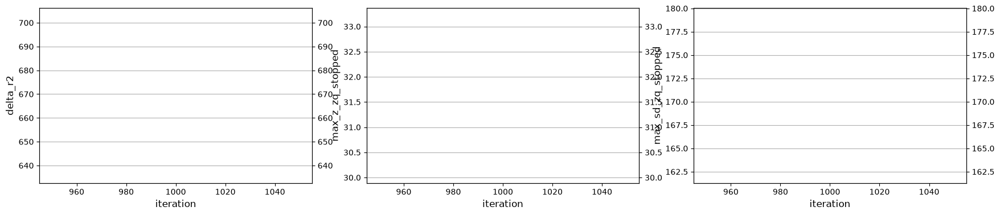

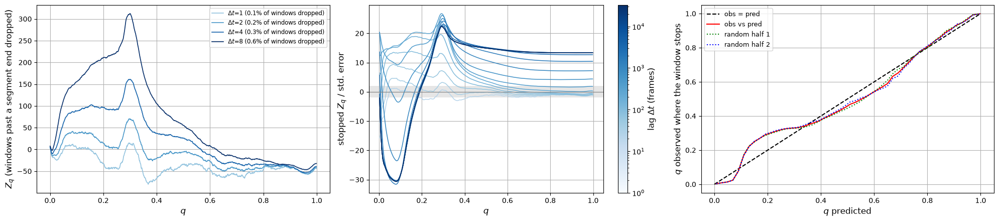

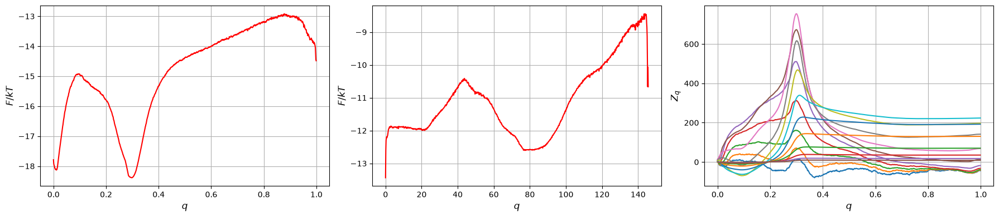

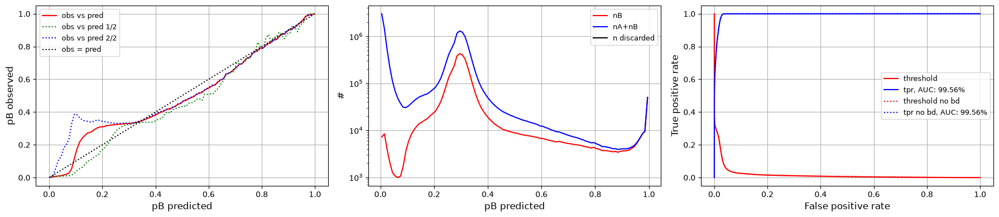

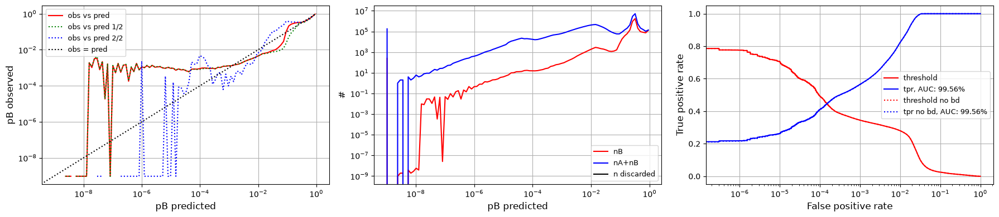

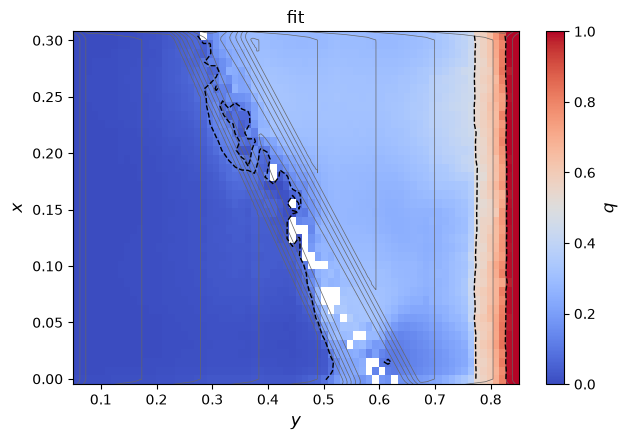

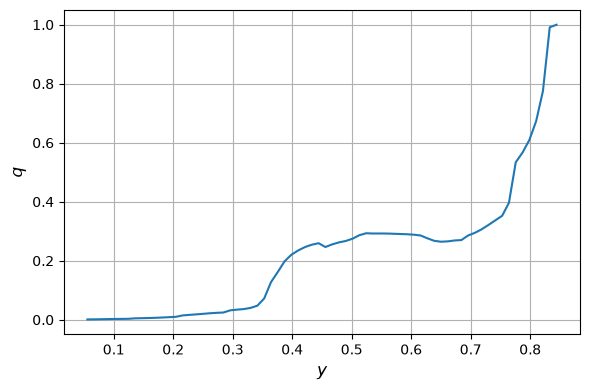

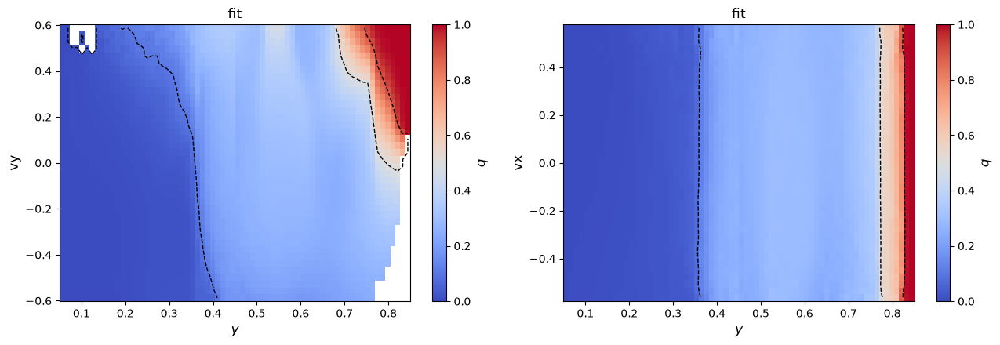

1000 iterations (warm-up, envelope 1000000) | zqs_z 31.63
#=1500, dr2=669.052, zqs_z=29.5946, sdzqs=113.517, |dx|=0.0222799, time=25.7171
#=2000, dr2=670.155, zqs_z=28.7002, sdzqs=113.309, |dx|=0.0121148, time=51.4943
#=2500, dr2=665.41, zqs_z=27.9427, sdzqs=113.214, |dx|=0.00542805, time=98.1329
#=3000, dr2=654.597, zqs_z=28.2822, sdzqs=110.319, |dx|=0.00540399, time=134.75
#=3500, dr2=648.338, zqs_z=29.3047, sdzqs=111.713, |dx|=0.00515661, time=174.807
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it3500 ---


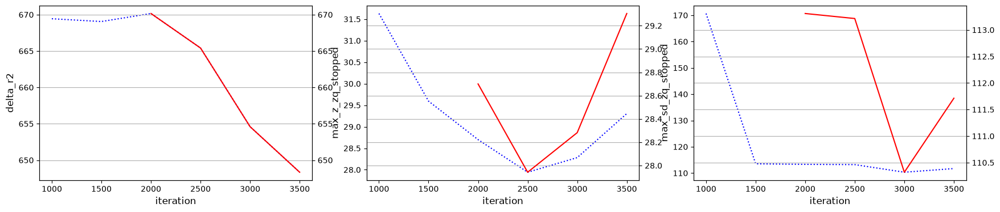

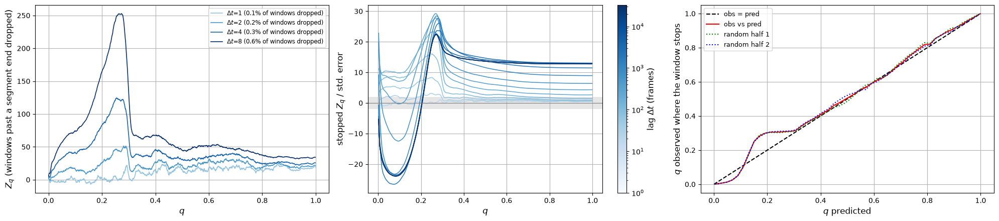

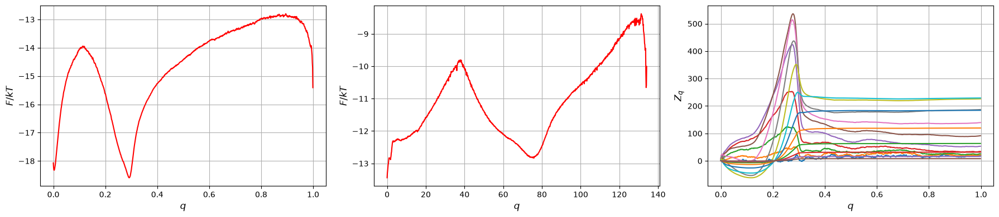

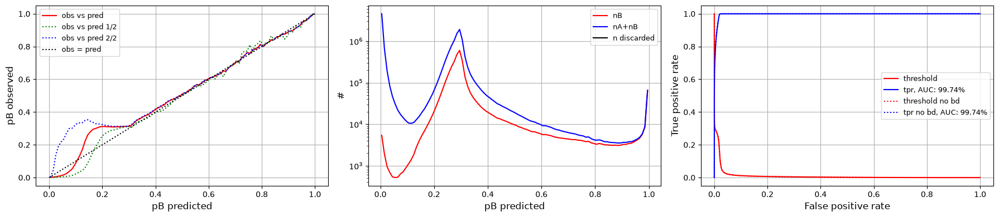

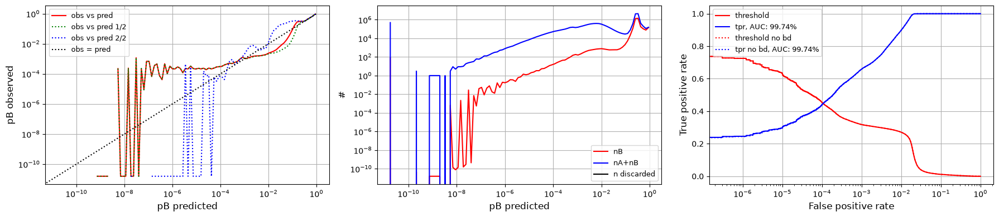

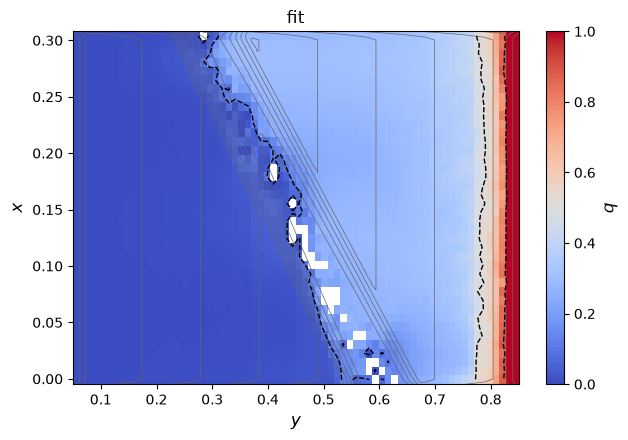

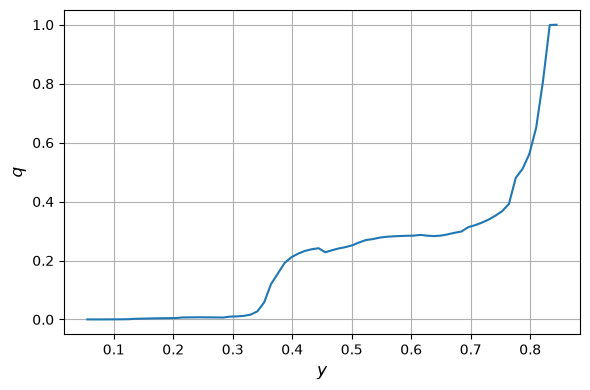

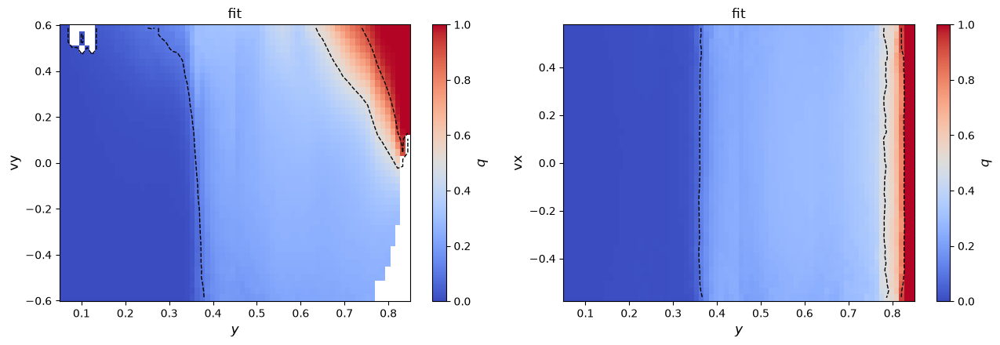

3500 iterations (main, envelope 0.01) | zqs_z 29.30
#=4000, dr2=647.016, zqs_z=29.6068, sdzqs=115.447, |dx|=0.00654935, time=45.7805
#=4500, dr2=639.212, zqs_z=30.2504, sdzqs=113.557, |dx|=0.00592878, time=93.8483
#=5000, dr2=634.322, zqs_z=29.6769, sdzqs=114.852, |dx|=0.00540475, time=124.779
#=5500, dr2=630.871, zqs_z=29.2772, sdzqs=115.544, |dx|=0.00523308, time=167.867
#=6000, dr2=612.89, zqs_z=28.4527, sdzqs=114.488, |dx|=0.00717812, time=215.859
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it6000 ---


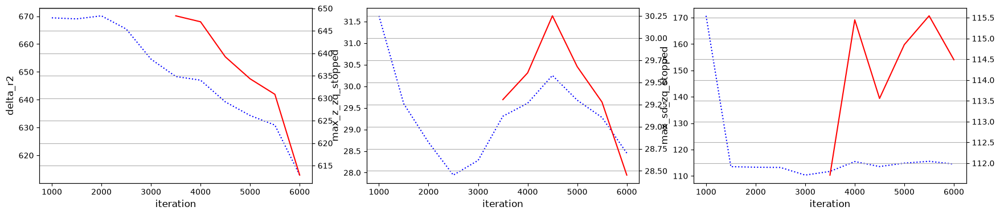

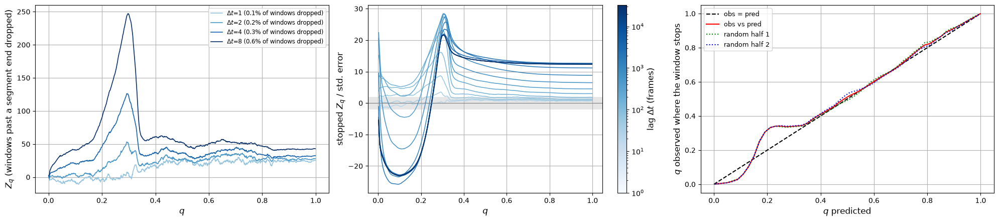

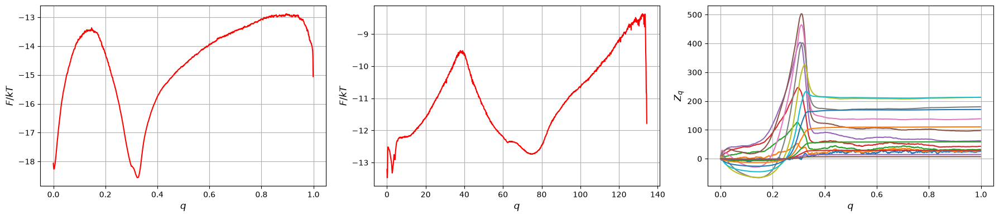

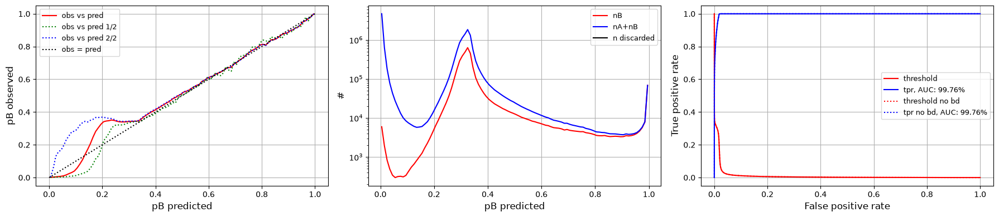

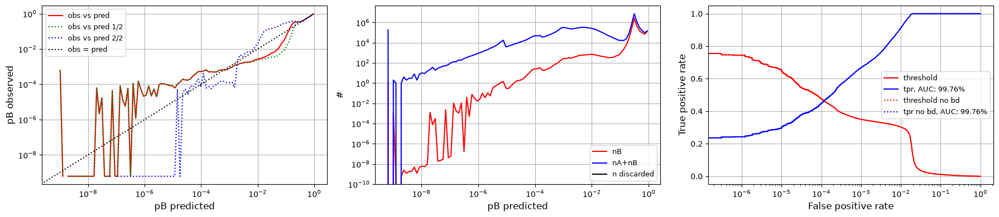

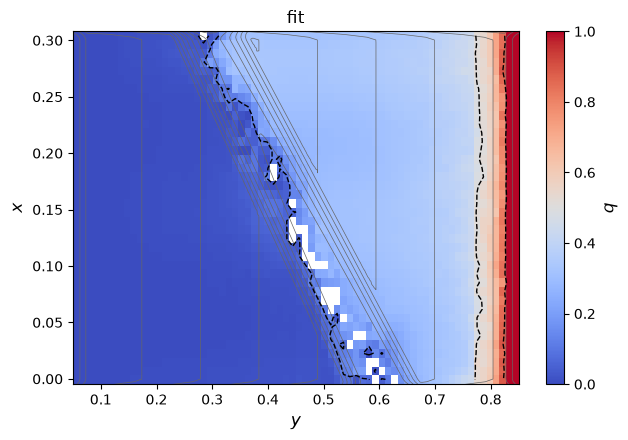

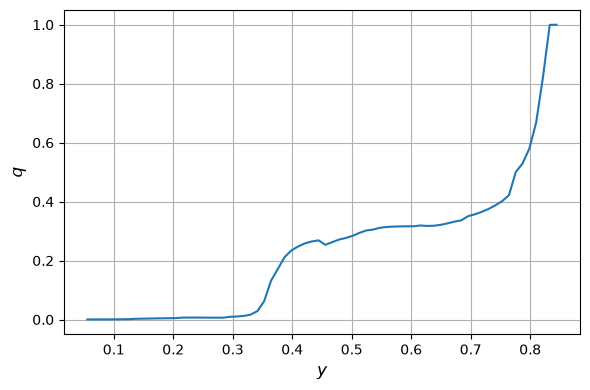

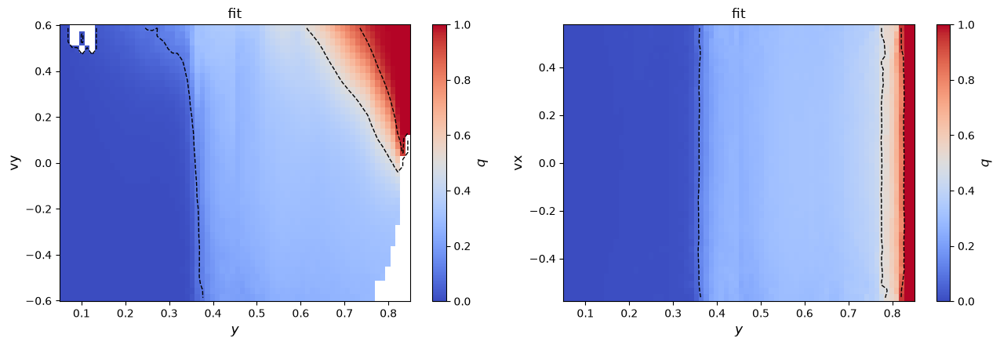

6000 iterations (main, envelope 0.01) | zqs_z 28.45
#=6500, dr2=608.616, zqs_z=28.6489, sdzqs=115.32, |dx|=0.00641763, time=47.6429
#=7000, dr2=600.017, zqs_z=28.4178, sdzqs=115.098, |dx|=0.0070691, time=75.3654
#=7500, dr2=590.795, zqs_z=27.5384, sdzqs=113.076, |dx|=0.00604801, time=121.975
#=8000, dr2=586.205, zqs_z=27.3399, sdzqs=113.5, |dx|=0.00579796, time=170.252
#=8500, dr2=580.967, zqs_z=27.3222, sdzqs=113.086, |dx|=0.00508536, time=216.542
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it8500 ---


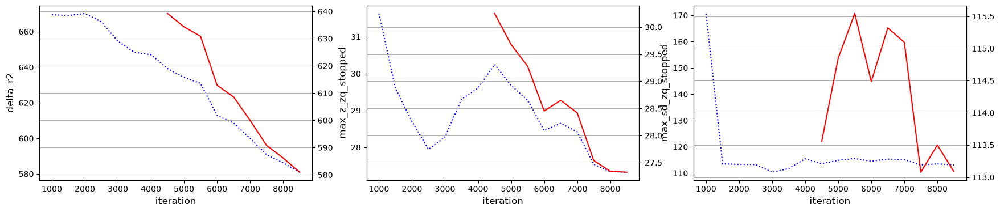

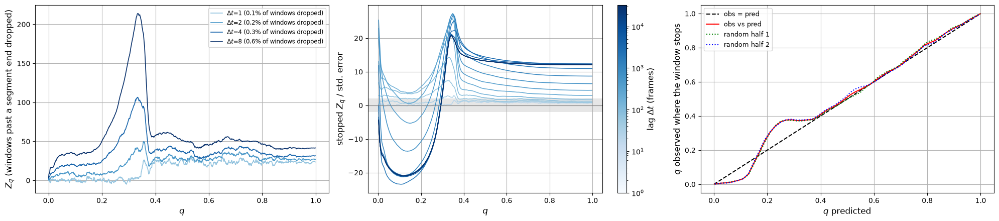

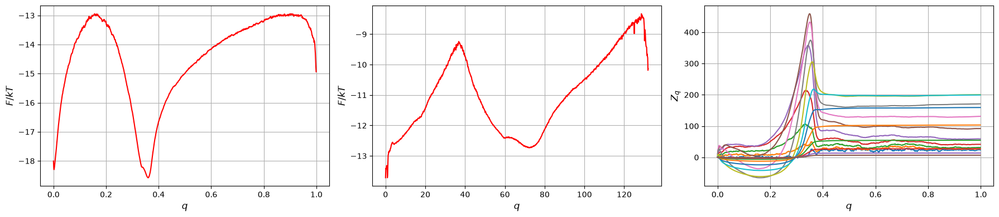

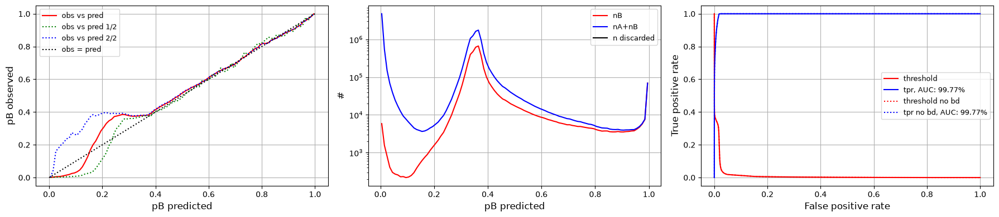

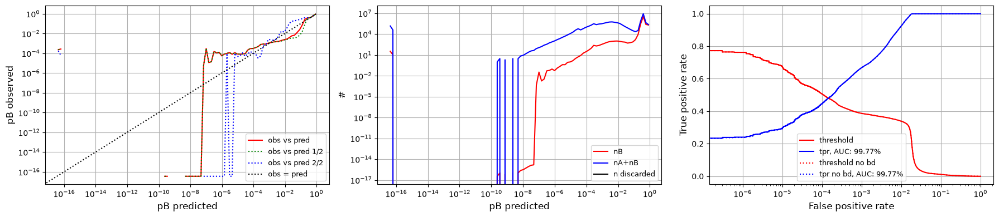

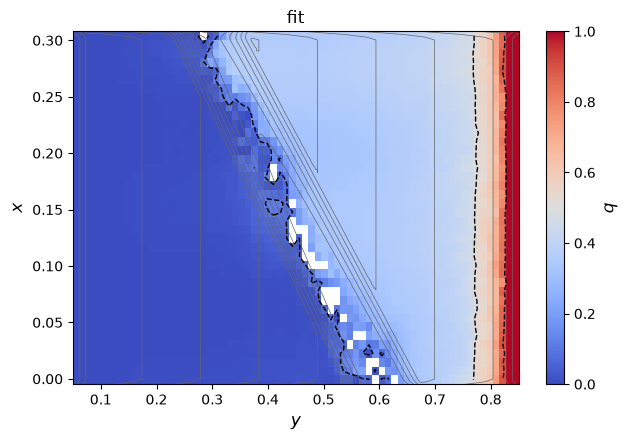

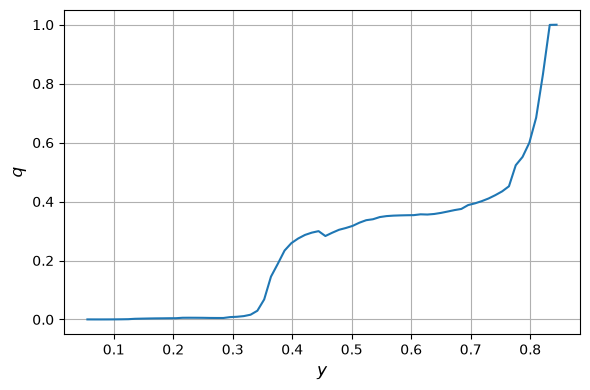

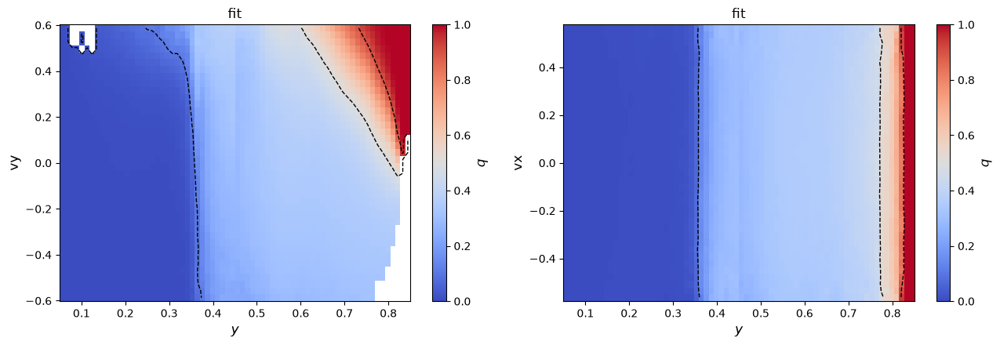

8500 iterations (main, envelope 0.01) | zqs_z 27.32
#=9000, dr2=571.881, zqs_z=26.7685, sdzqs=109.46, |dx|=0.00442875, time=29.4107
#=9500, dr2=566.19, zqs_z=26.6491, sdzqs=108.259, |dx|=0.00523641, time=77.6847
#=10000, dr2=564.624, zqs_z=26.5921, sdzqs=107.954, |dx|=0.00415737, time=123.844
#=10500, dr2=558.892, zqs_z=26.1986, sdzqs=106.406, |dx|=0.00347506, time=172.218
#=11000, dr2=555.776, zqs_z=26.1905, sdzqs=106.463, |dx|=0.00286785, time=202.78
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it11000 ---


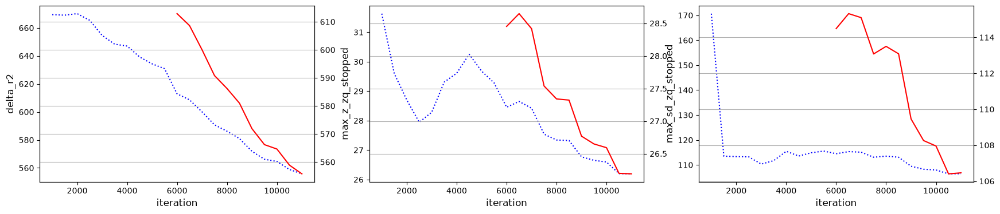

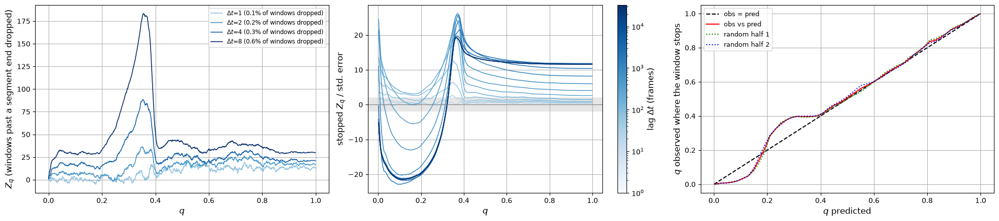

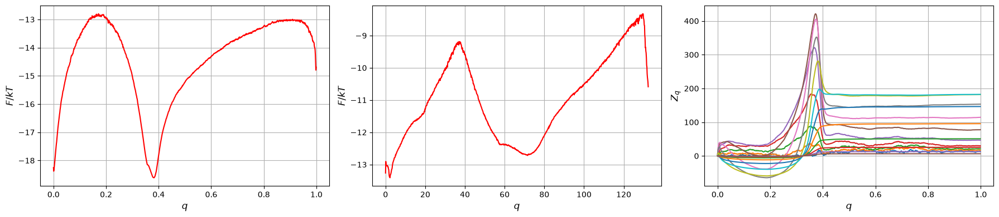

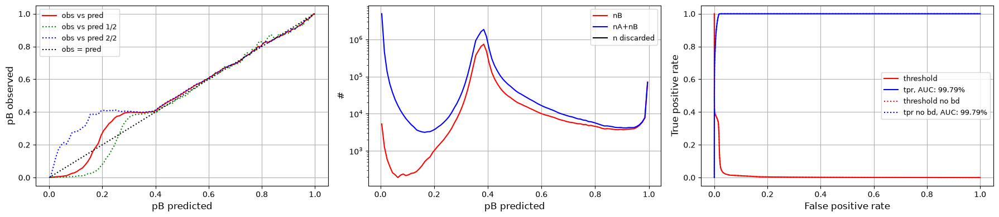

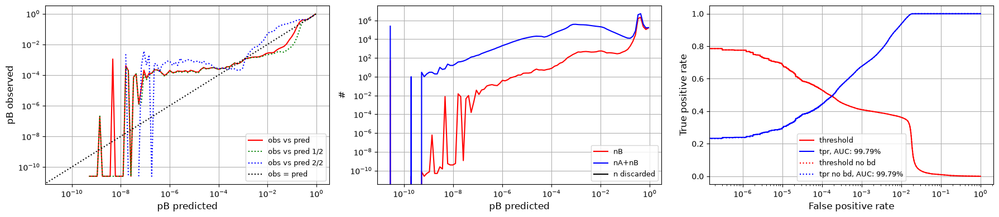

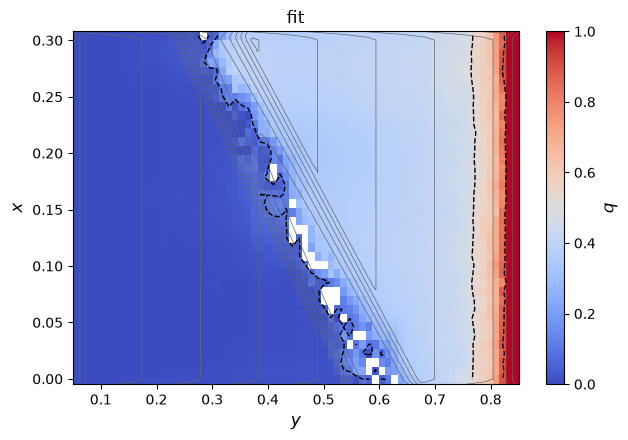

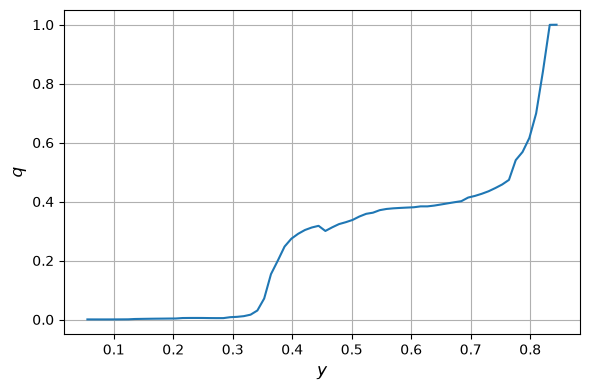

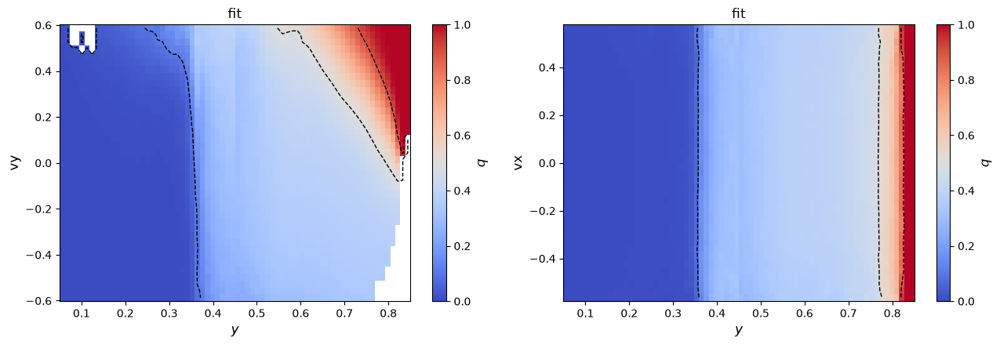

11000 iterations (main, envelope 0.01) | zqs_z 26.19
#=11500, dr2=552.511, zqs_z=26.1756, sdzqs=107.718, |dx|=0.00434348, time=47.357
#=12000, dr2=547.562, zqs_z=25.8713, sdzqs=105.931, |dx|=0.00375858, time=95.703
#=12500, dr2=543.728, zqs_z=25.5102, sdzqs=104.972, |dx|=0.00333498, time=143.636
#=13000, dr2=537.81, zqs_z=25.1307, sdzqs=104.518, |dx|=0.00448792, time=171.268
#=13500, dr2=534.474, zqs_z=24.9497, sdzqs=105.703, |dx|=0.00390017, time=219.317
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it13500 ---


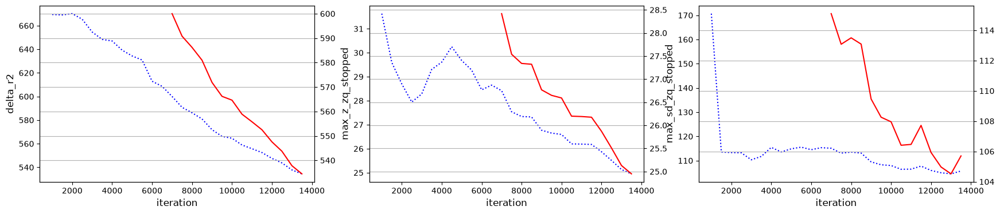

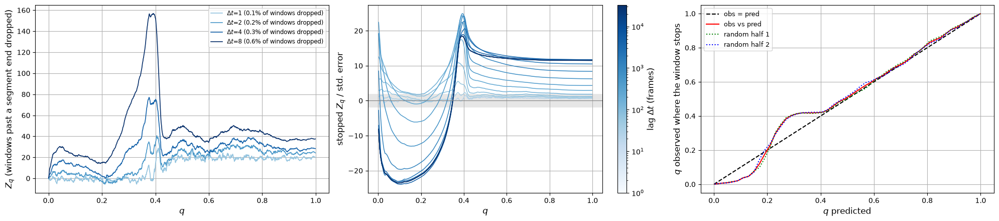

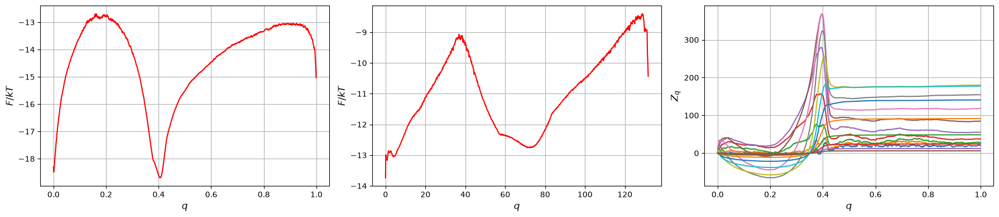

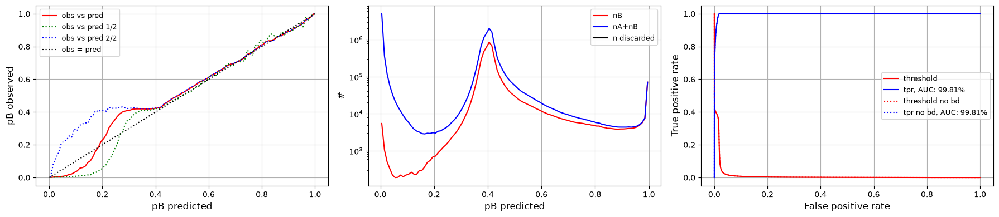

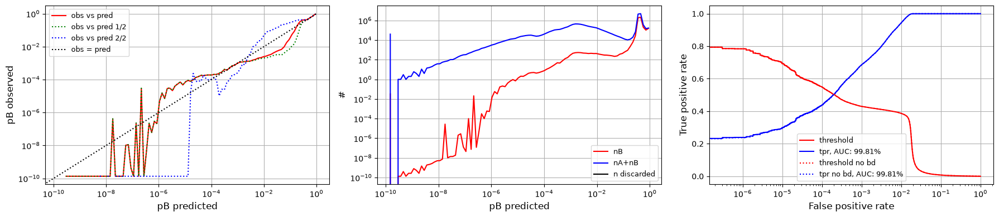

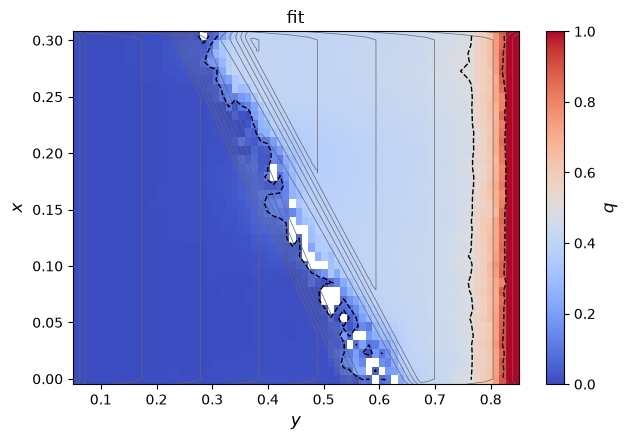

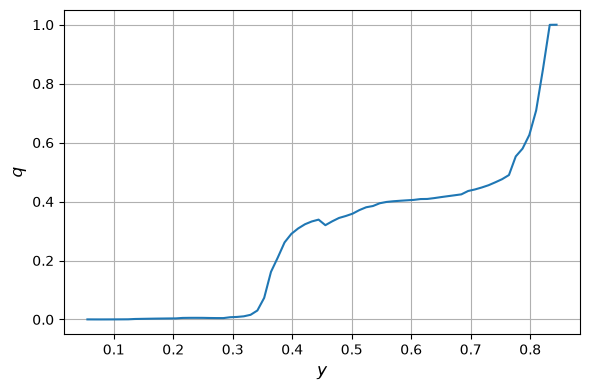

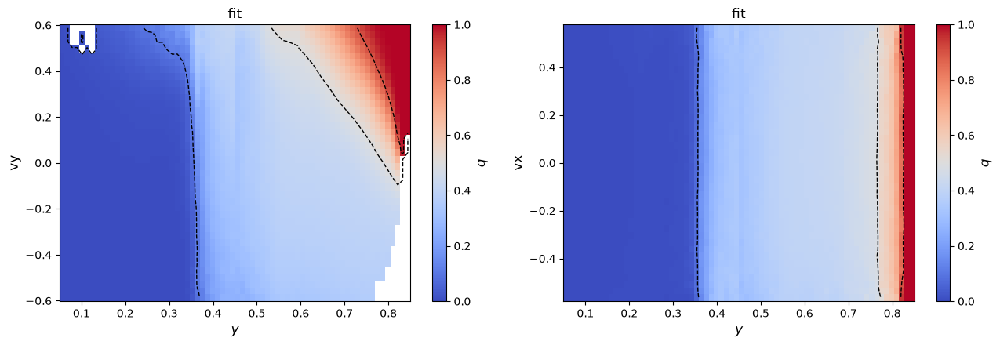

13500 iterations (main, envelope 0.01) | zqs_z 24.95
#=14000, dr2=528.537, zqs_z=24.8049, sdzqs=104.307, |dx|=0.00400852, time=47.8541
#=14500, dr2=520.795, zqs_z=24.4893, sdzqs=102.271, |dx|=0.0039843, time=92.7858
#=15000, dr2=517.55, zqs_z=24.7171, sdzqs=103.439, |dx|=0.00539907, time=122.834
#=15500, dr2=510.046, zqs_z=24.2504, sdzqs=101.717, |dx|=0.00587776, time=171.265
#=16000, dr2=501.267, zqs_z=24.5126, sdzqs=103.007, |dx|=0.00663392, time=217.554
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it16000 ---


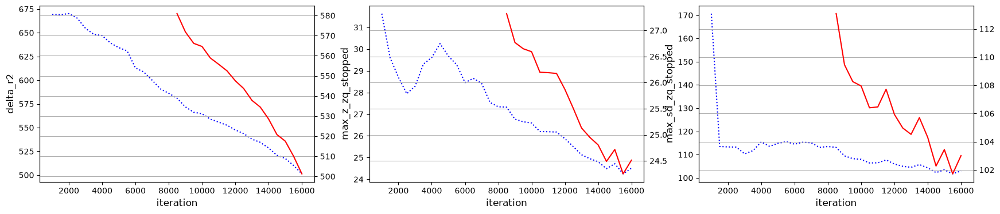

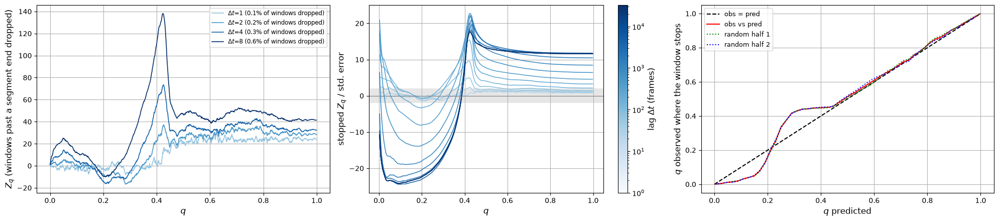

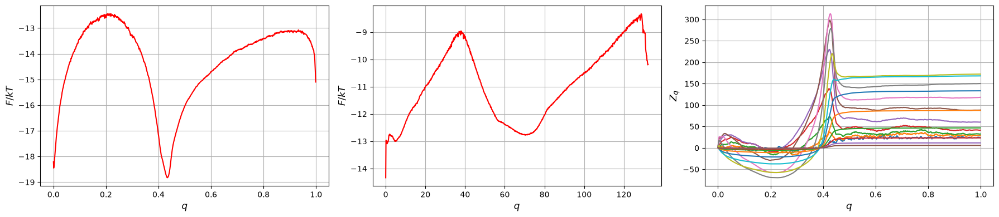

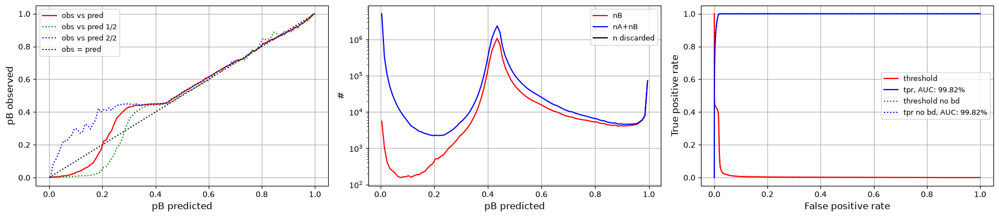

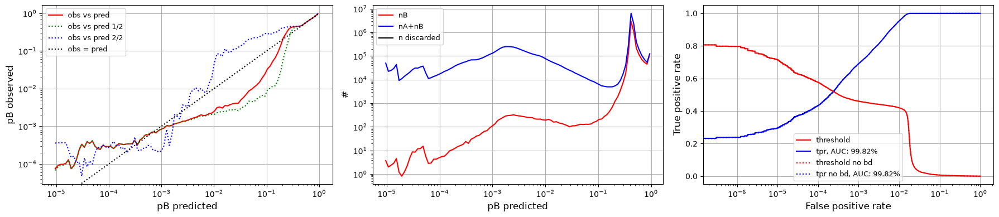

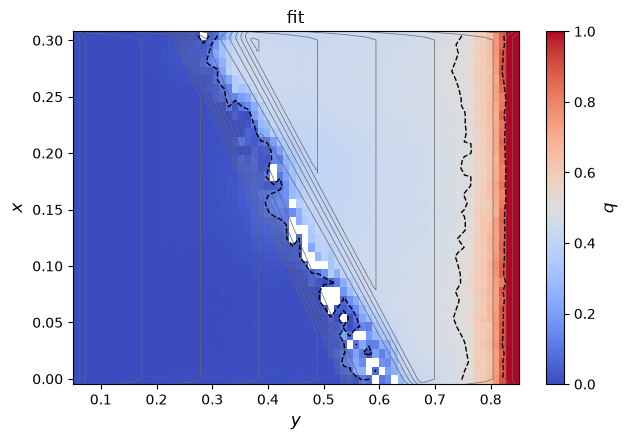

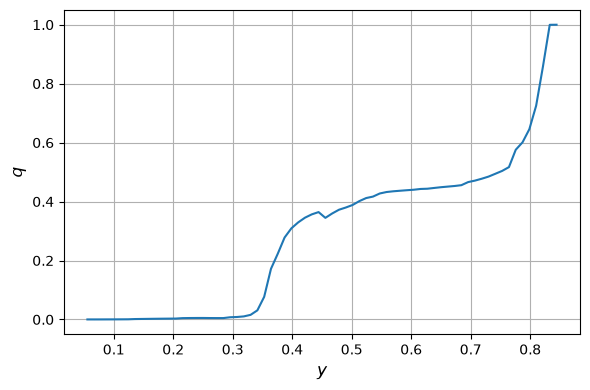

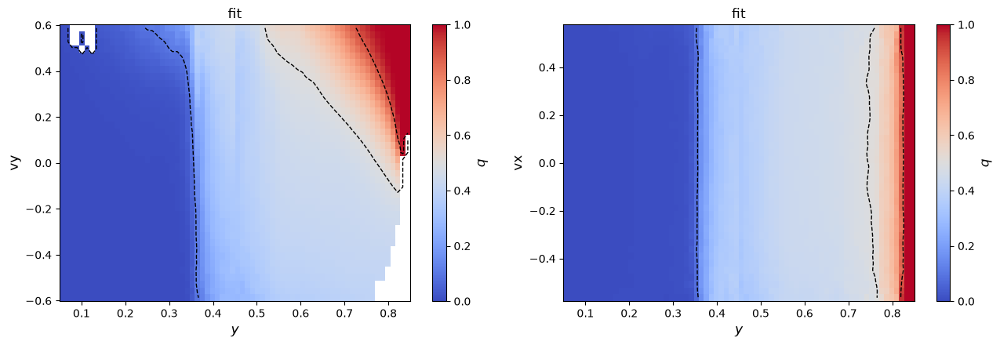

16000 iterations (main, envelope 0.01) | zqs_z 24.51
#=16500, dr2=488.91, zqs_z=24.3919, sdzqs=102.425, |dx|=0.00711204, time=39.849
#=17000, dr2=480.651, zqs_z=25.0277, sdzqs=103.6, |dx|=0.00796907, time=76.0165
#=17500, dr2=469.629, zqs_z=24.8039, sdzqs=104.078, |dx|=0.00806804, time=122.95
#=18000, dr2=454.515, zqs_z=24.485, sdzqs=103.658, |dx|=0.00866456, time=171.332
#=18500, dr2=441.326, zqs_z=25.4527, sdzqs=101.72, |dx|=0.0094689, time=218.559
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it18500 ---


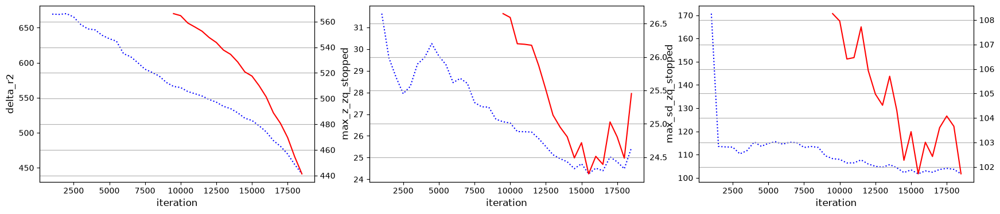

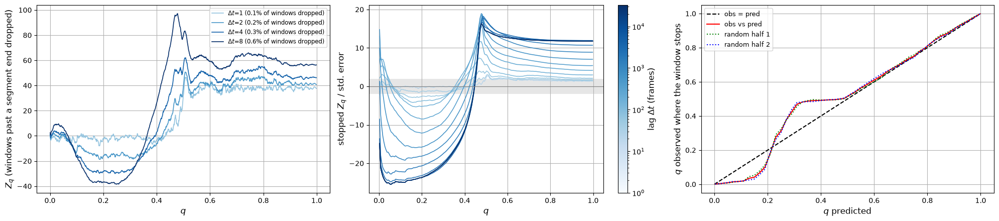

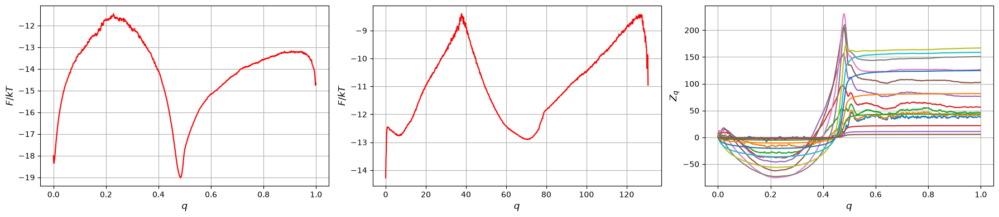

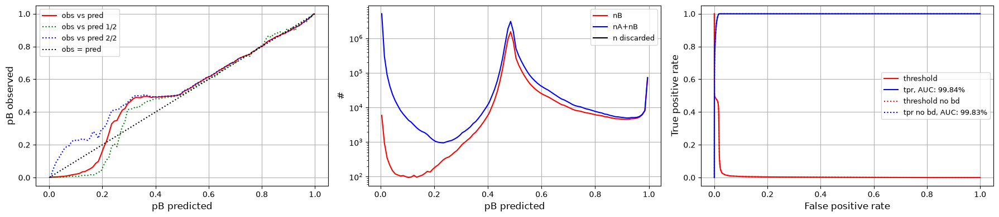

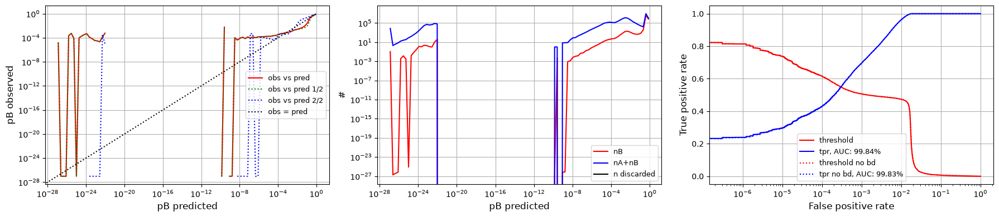

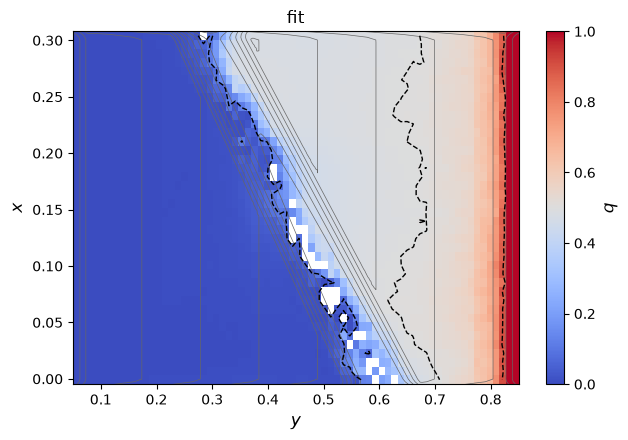

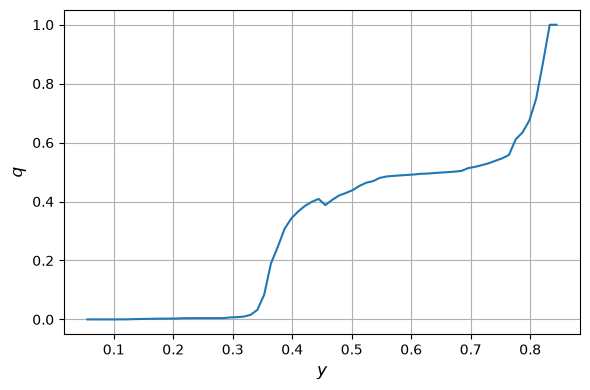

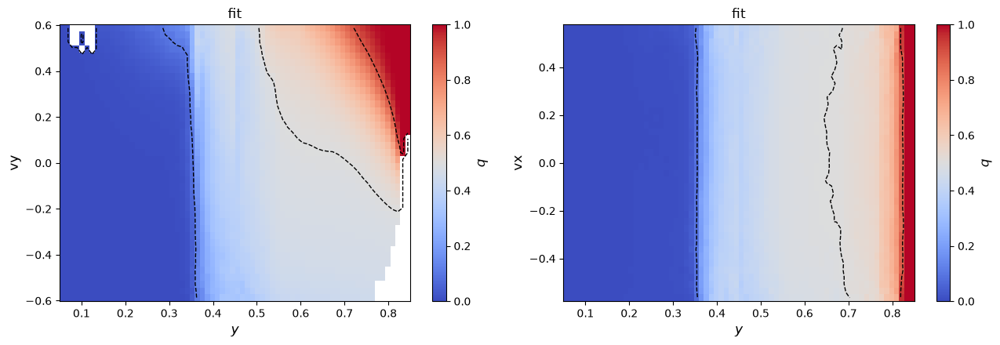

18500 iterations (main, envelope 0.01) | zqs_z 25.45
#=19000, dr2=424.178, zqs_z=25.0361, sdzqs=97.6766, |dx|=0.0107884, time=40.1935
#=19500, dr2=408.985, zqs_z=24.7717, sdzqs=97.1306, |dx|=0.0115166, time=88.2485
#=20000, dr2=395.528, zqs_z=23.9417, sdzqs=94.4378, |dx|=0.0112419, time=136.462
#=20500, dr2=379.906, zqs_z=23.2314, sdzqs=88.1966, |dx|=0.0123935, time=180.461
#=21000, dr2=367.056, zqs_z=22.634, sdzqs=86.8956, |dx|=0.0105379, time=211.715
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_rejections_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it21000 ---


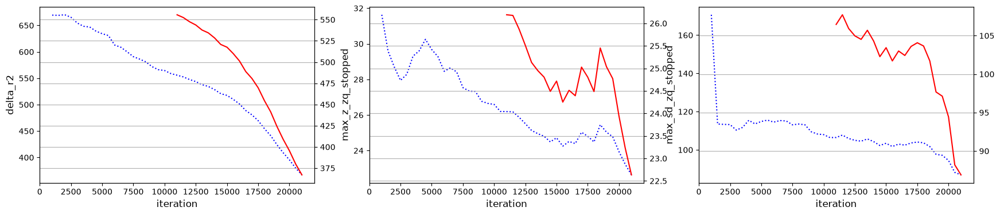

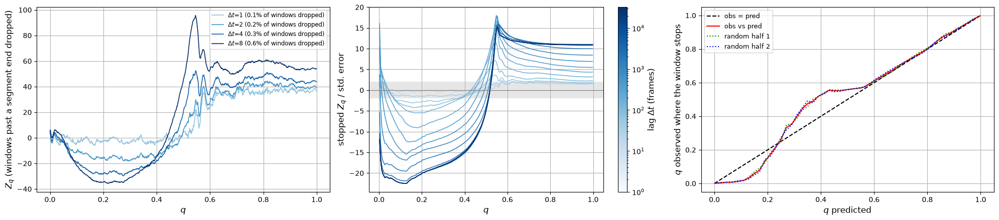

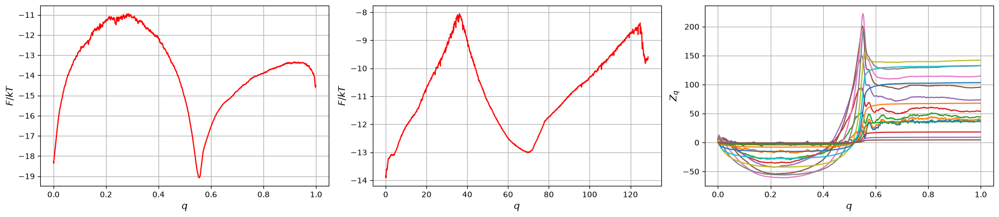

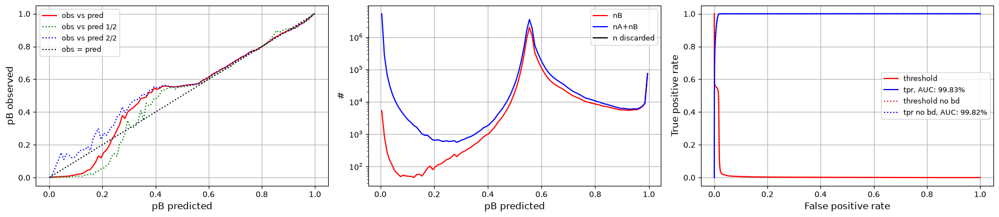

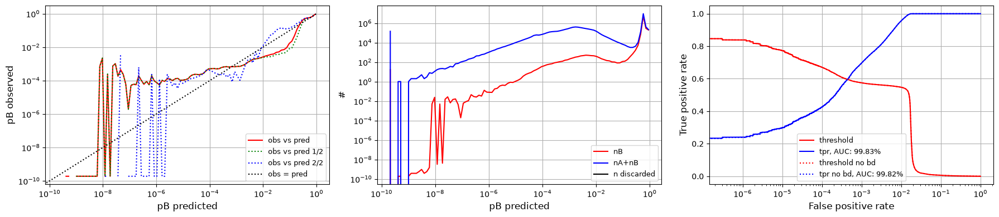

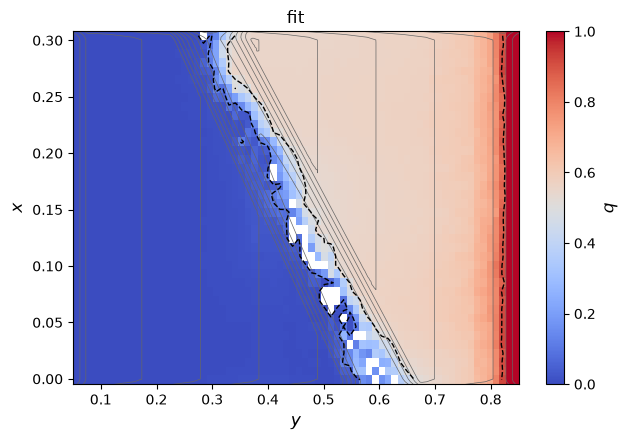

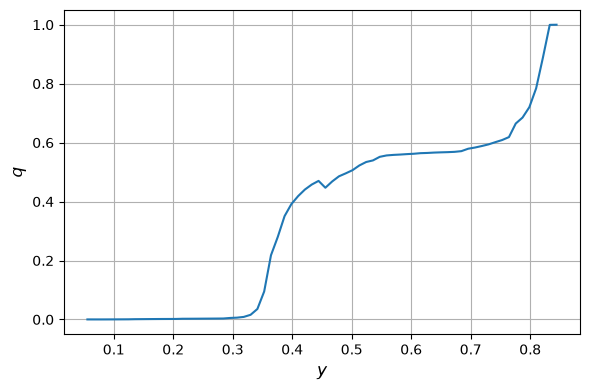

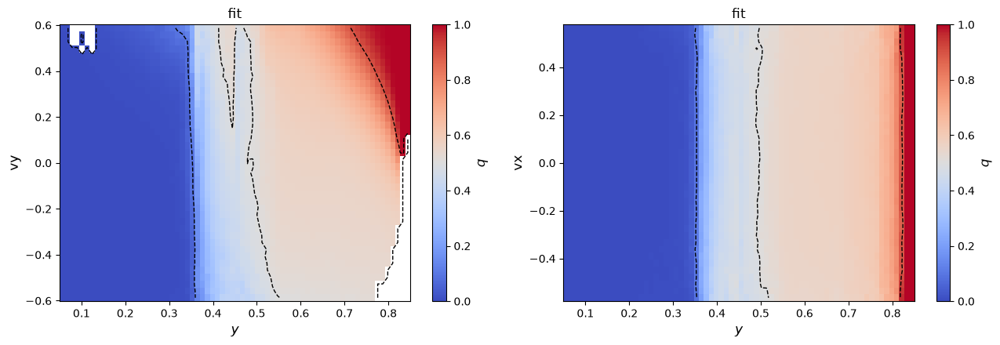

21000 iterations (main, envelope 0.01) | zqs_z 22.63
===== fit, without weights, seed 0: rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped =====
#=500, dr2=621.777, zqs_z=44.7894, sdzqs=257.101, |dx|=0.34926, time=48.0361
#=1000, dr2=664.079, zqs_z=38.2552, sdzqs=110.66, |dx|=0.0451717, time=94.2578
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it1000 ---


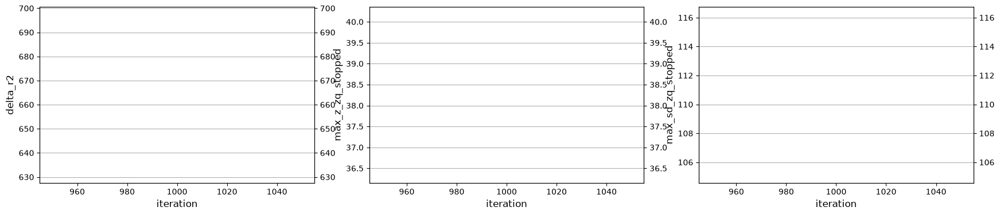

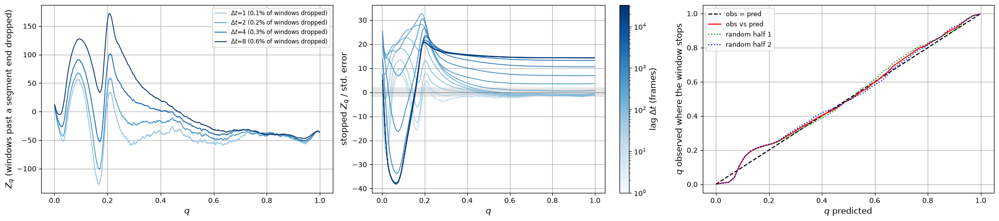

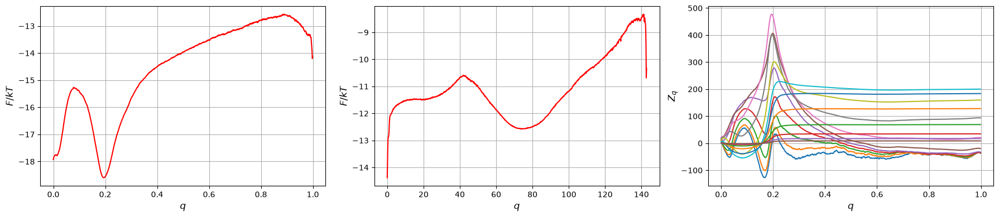

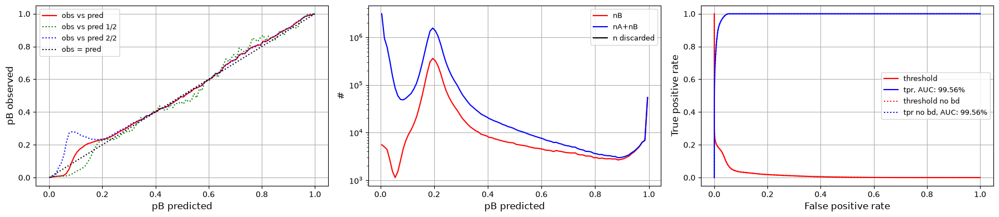

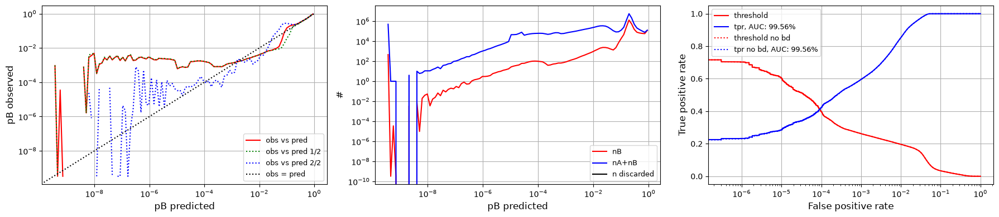

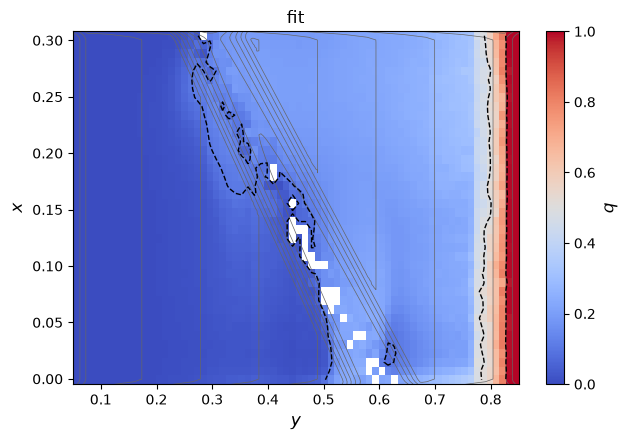

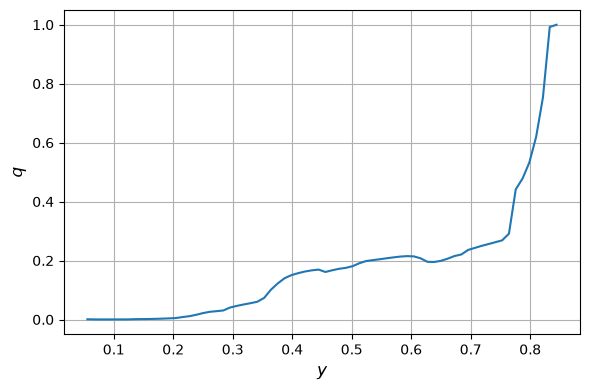

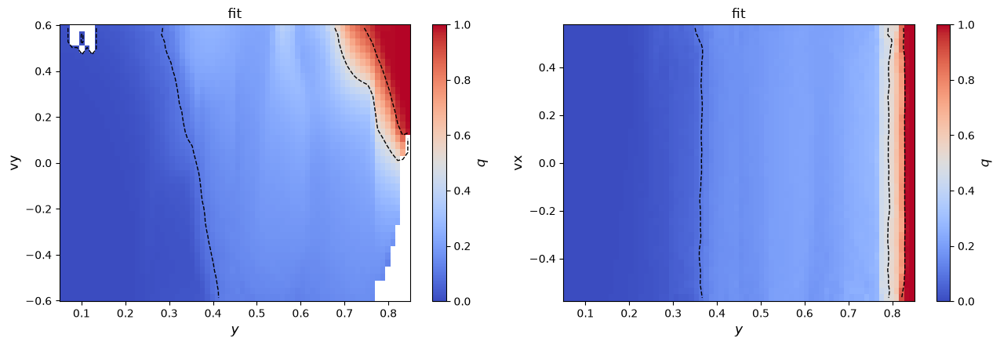

1000 iterations (warm-up, envelope 1000000) | zqs_z 38.26
#=1500, dr2=665.596, zqs_z=37.5172, sdzqs=102.418, |dx|=0.0145873, time=27.1135
#=2000, dr2=664.074, zqs_z=34.9122, sdzqs=109, |dx|=0.0101373, time=52.9372
#=2500, dr2=654.288, zqs_z=34.5357, sdzqs=111.239, |dx|=0.00846906, time=78.7363
#=3000, dr2=642.337, zqs_z=34.6115, sdzqs=109.573, |dx|=0.00763006, time=104.526
#=3500, dr2=631.131, zqs_z=35.7059, sdzqs=110.821, |dx|=0.00747399, time=130.298
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it3500 ---


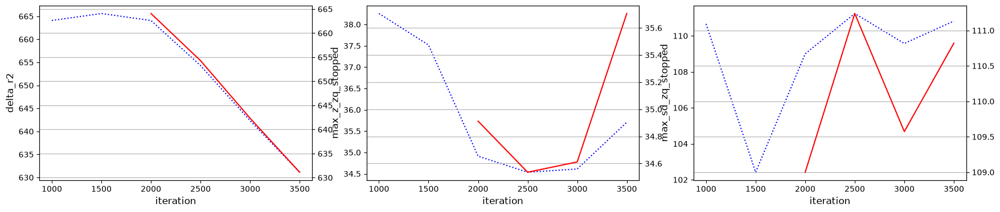

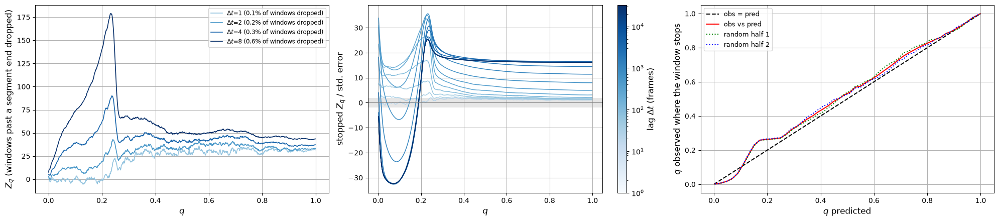

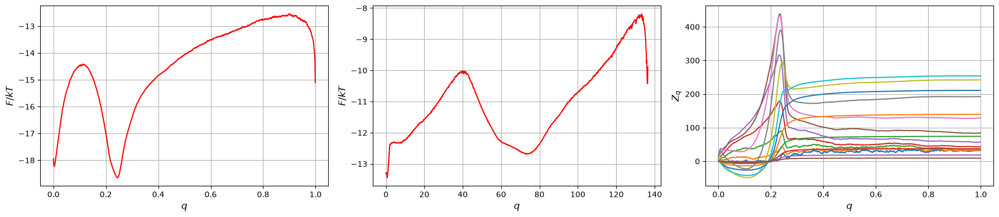

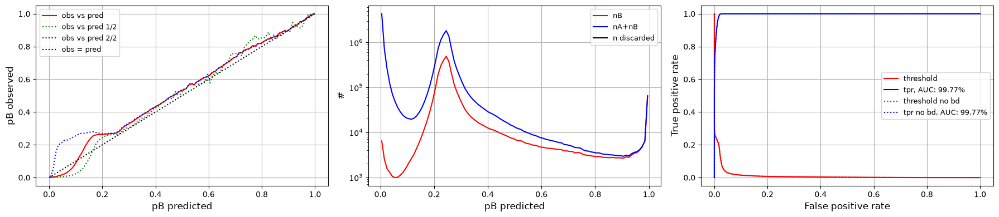

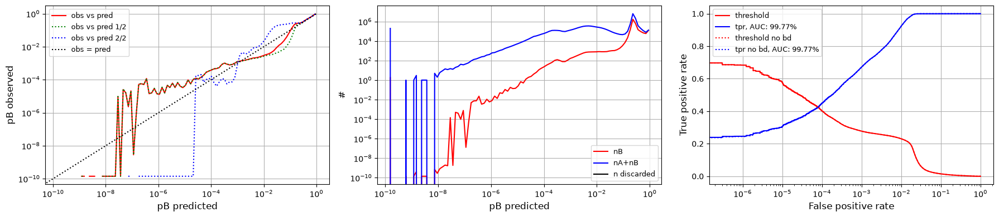

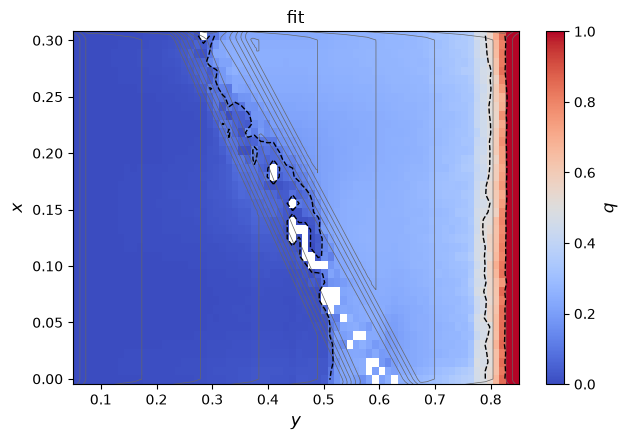

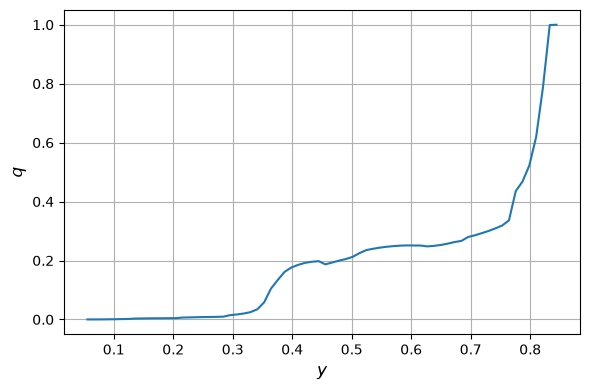

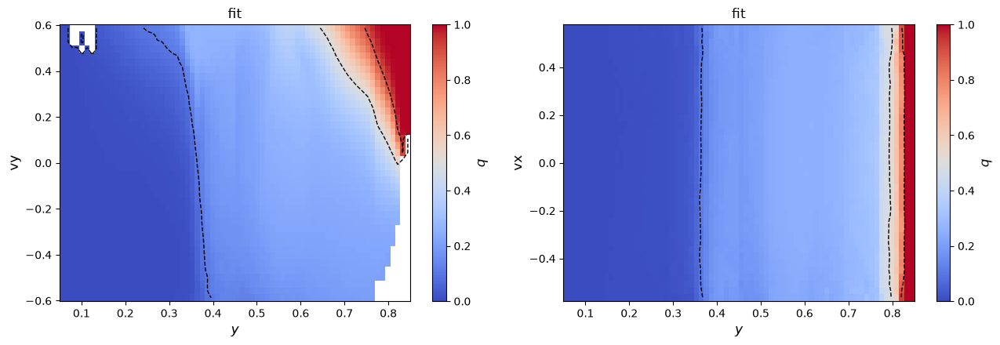

3500 iterations (main, envelope 0.01) | zqs_z 35.71
#=4000, dr2=626.751, zqs_z=35.8303, sdzqs=114.268, |dx|=0.00873732, time=25.6591
#=4500, dr2=618.399, zqs_z=36.1144, sdzqs=113.565, |dx|=0.00799818, time=51.4838
#=5000, dr2=611.433, zqs_z=36.167, sdzqs=113.258, |dx|=0.00709848, time=77.2875
#=5500, dr2=607.477, zqs_z=36.6103, sdzqs=114.574, |dx|=0.00651106, time=103.081
#=6000, dr2=590.356, zqs_z=36.0084, sdzqs=112.735, |dx|=0.00789363, time=128.866
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it6000 ---


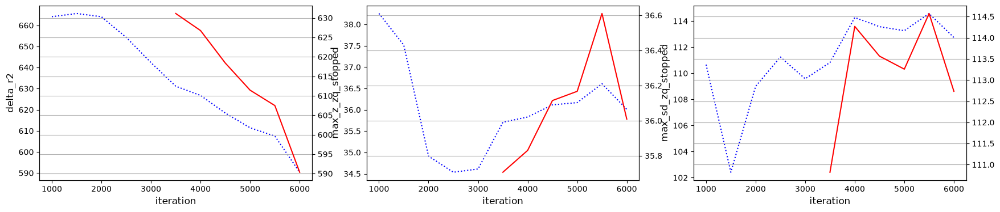

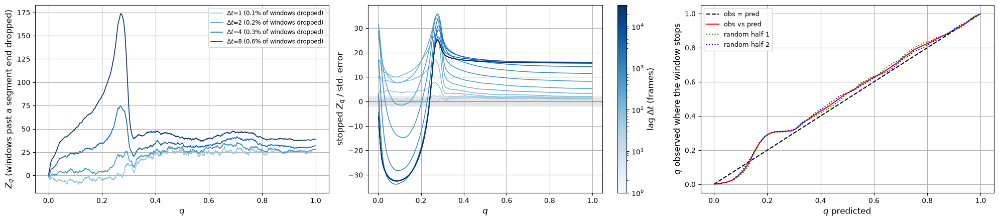

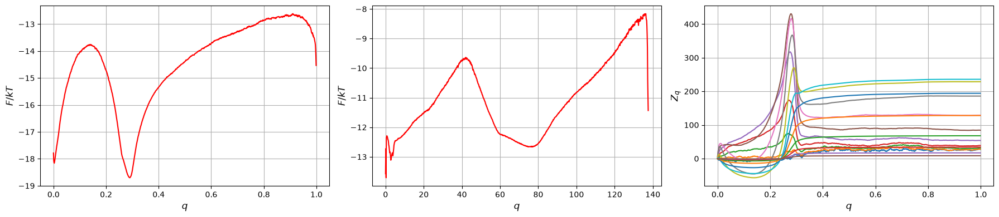

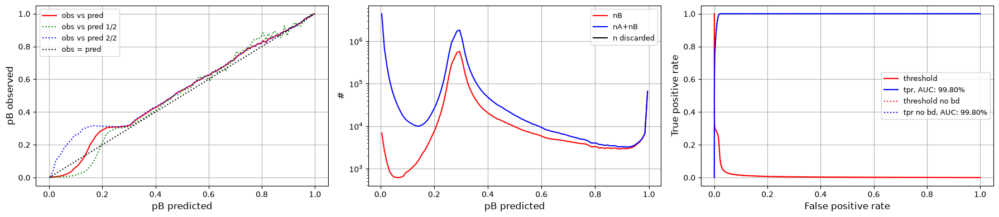

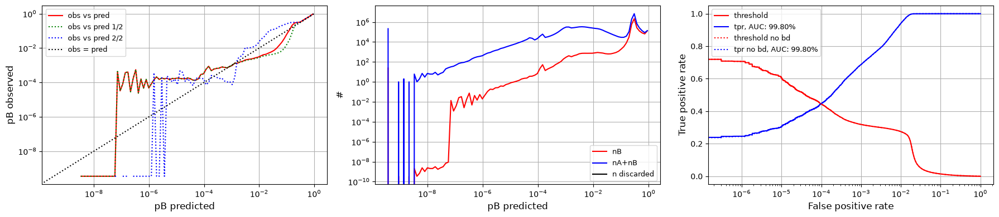

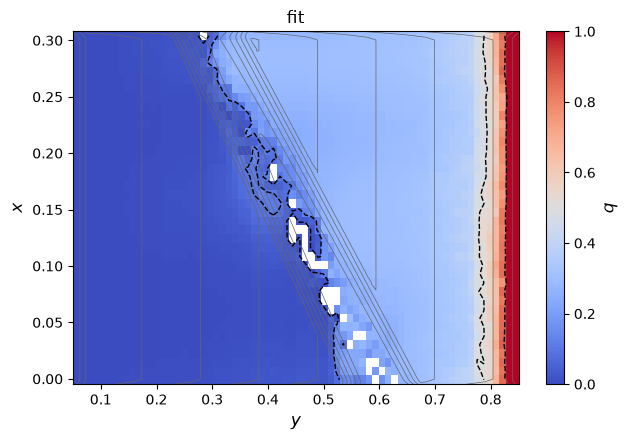

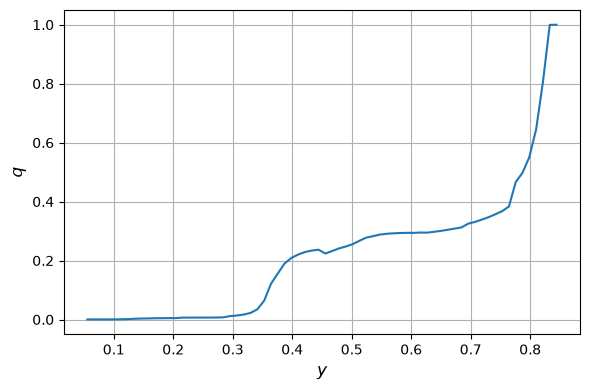

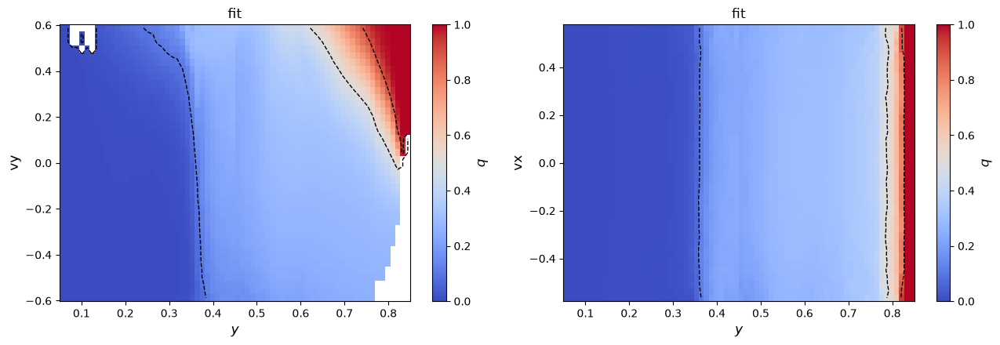

6000 iterations (main, envelope 0.01) | zqs_z 36.01
#=6500, dr2=586.528, zqs_z=36.8457, sdzqs=112.279, |dx|=0.0068028, time=25.666
#=7000, dr2=579.356, zqs_z=36.3432, sdzqs=113.605, |dx|=0.00692795, time=51.4384
#=7500, dr2=569.606, zqs_z=35.0935, sdzqs=114.162, |dx|=0.00673441, time=77.2209
#=8000, dr2=563.57, zqs_z=34.3559, sdzqs=115.5, |dx|=0.00748781, time=102.972
#=8500, dr2=556.312, zqs_z=33.4584, sdzqs=117.095, |dx|=0.00730463, time=128.746
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it8500 ---


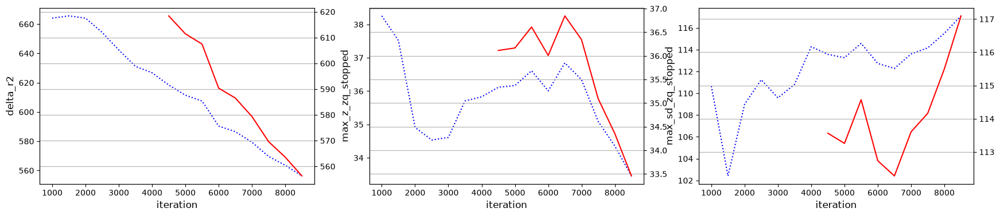

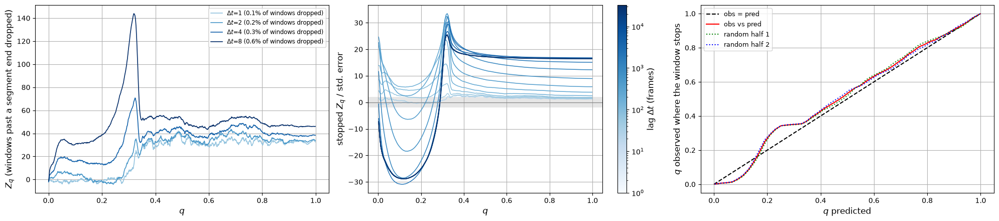

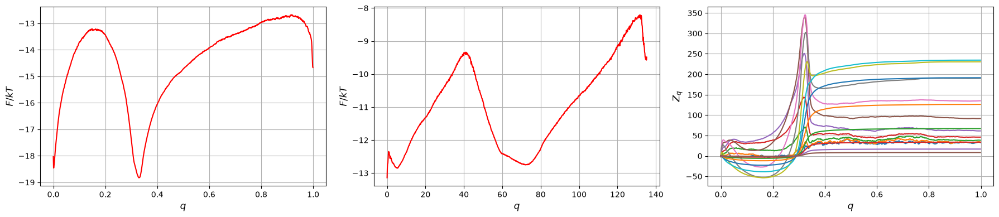

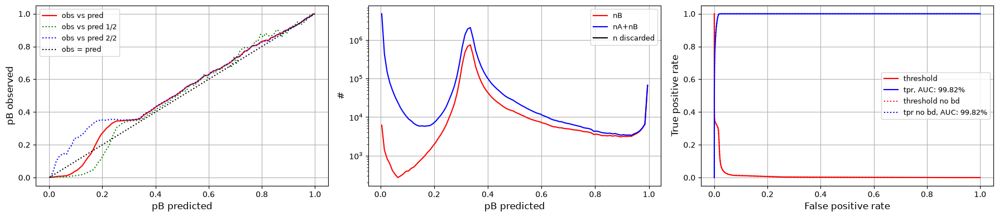

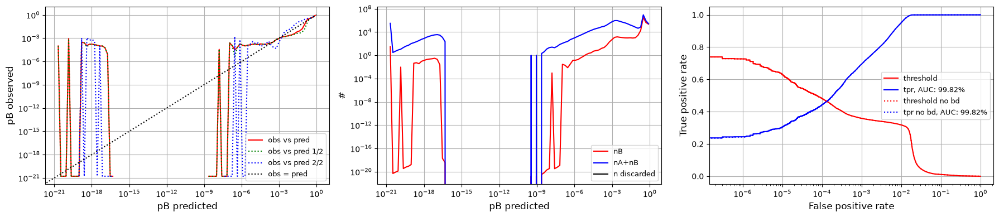

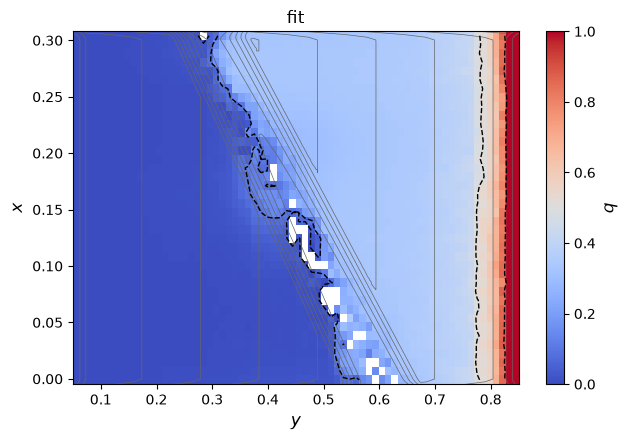

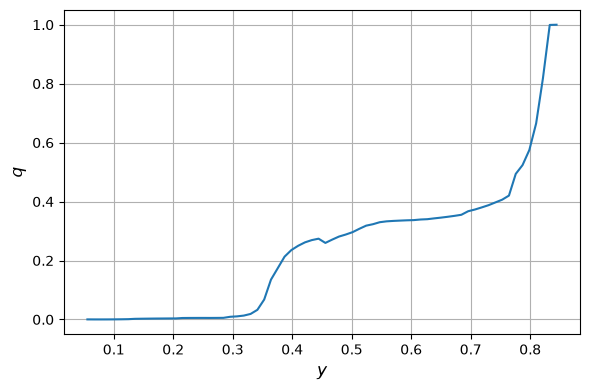

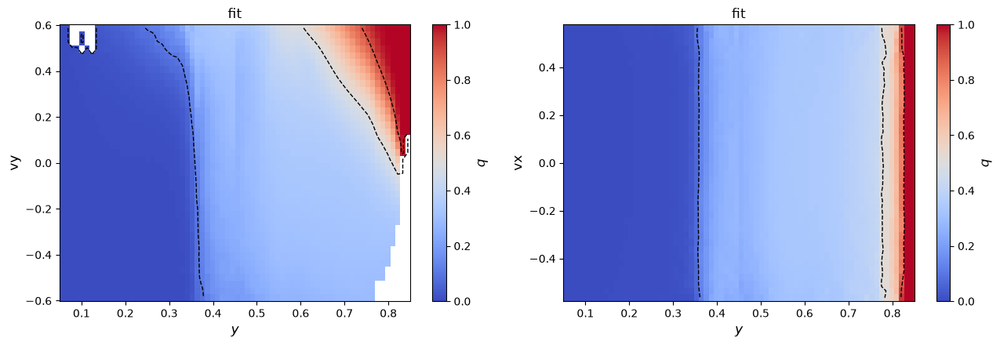

8500 iterations (main, envelope 0.01) | zqs_z 33.46
#=9000, dr2=542.803, zqs_z=32.4437, sdzqs=116.001, |dx|=0.00787652, time=25.6478
#=9500, dr2=529.846, zqs_z=31.4296, sdzqs=116.929, |dx|=0.010715, time=51.4833
#=10000, dr2=520.273, zqs_z=30.9368, sdzqs=120.822, |dx|=0.0106663, time=77.3161
#=10500, dr2=506.965, zqs_z=31.8514, sdzqs=120.93, |dx|=0.0104875, time=103.15
#=11000, dr2=492.385, zqs_z=32.6764, sdzqs=122.489, |dx|=0.0110678, time=129.05
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it11000 ---


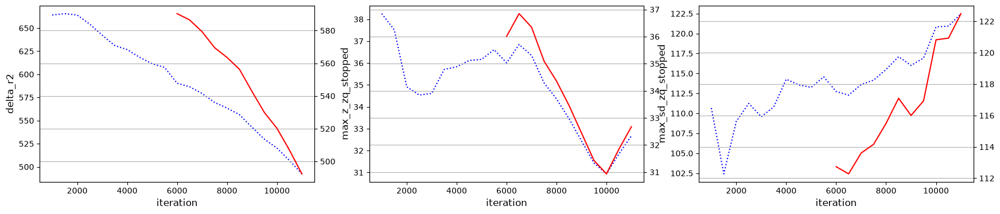

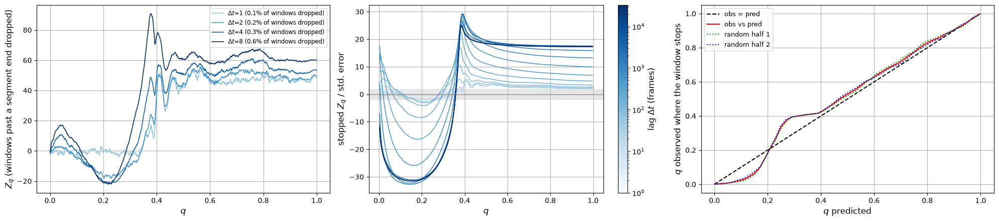

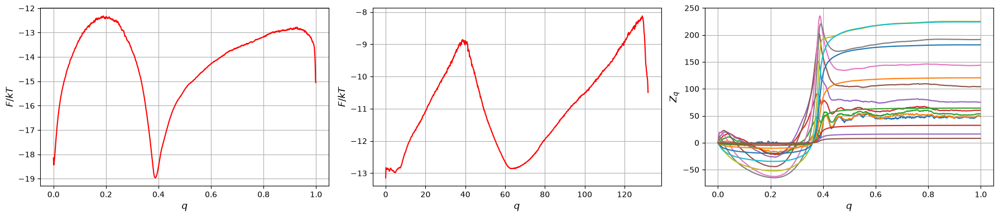

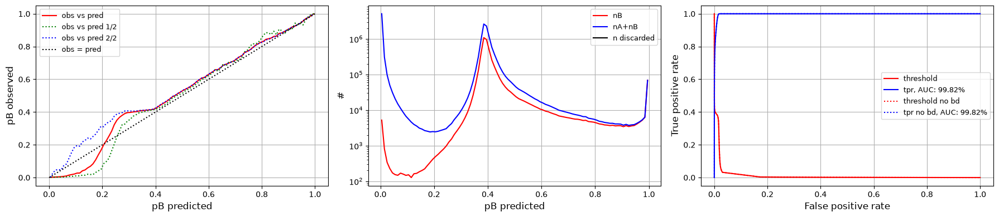

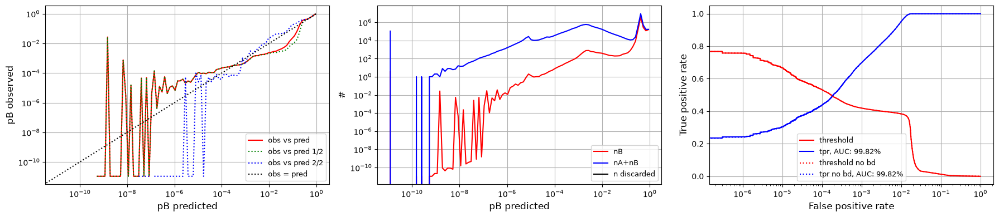

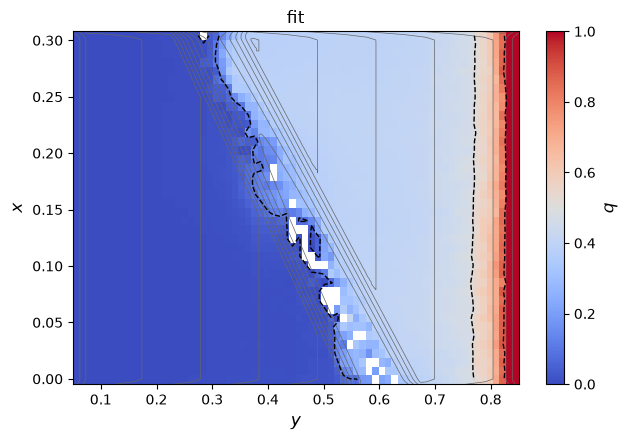

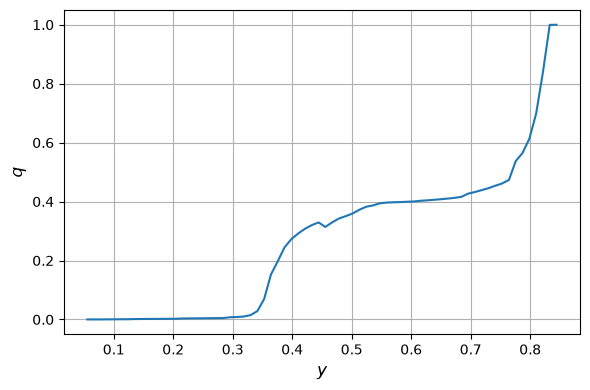

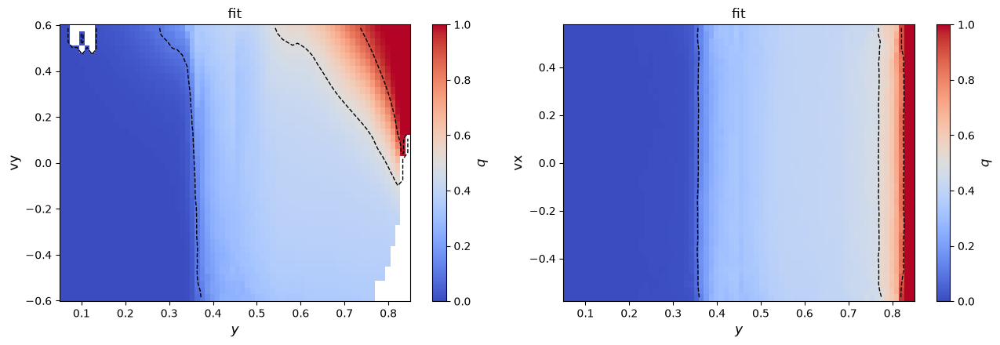

11000 iterations (main, envelope 0.01) | zqs_z 32.68
#=11500, dr2=470.633, zqs_z=32.3084, sdzqs=121.728, |dx|=0.0141765, time=25.6329
#=12000, dr2=449.701, zqs_z=31.8255, sdzqs=117.531, |dx|=0.0141332, time=51.4826
#=12500, dr2=434.333, zqs_z=30.3103, sdzqs=115.576, |dx|=0.0127462, time=77.4223
#=13000, dr2=420.231, zqs_z=28.325, sdzqs=109.217, |dx|=0.0144704, time=103.364
#=13500, dr2=408.916, zqs_z=28.1363, sdzqs=106.928, |dx|=0.0114569, time=129.259
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it13500 ---


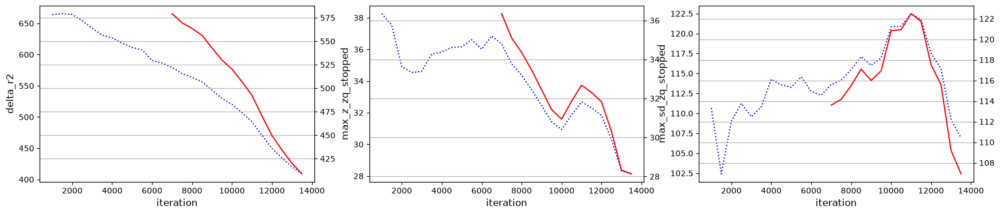

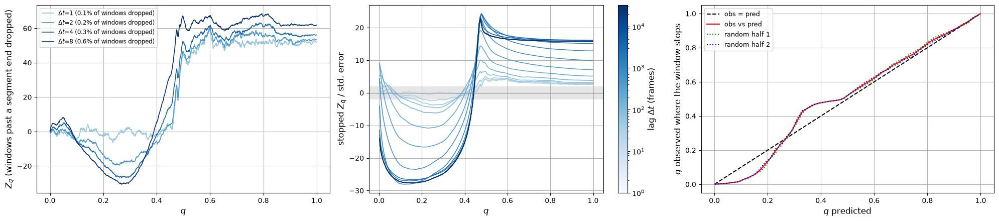

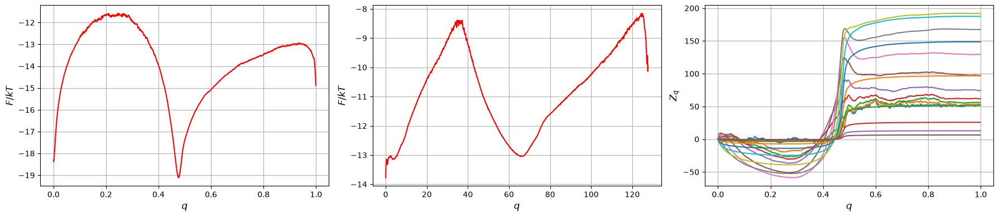

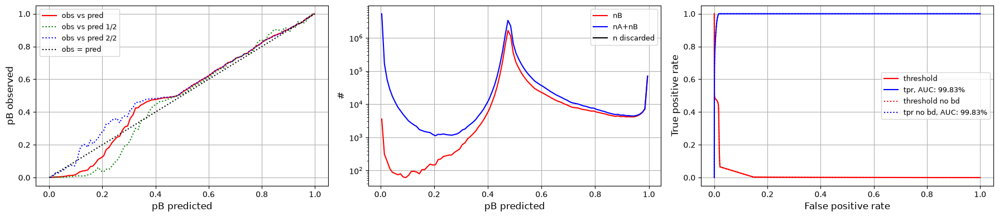

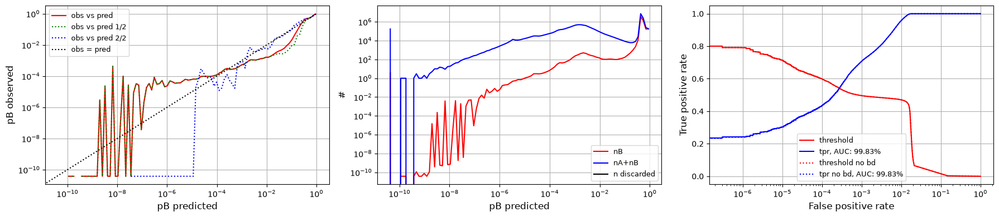

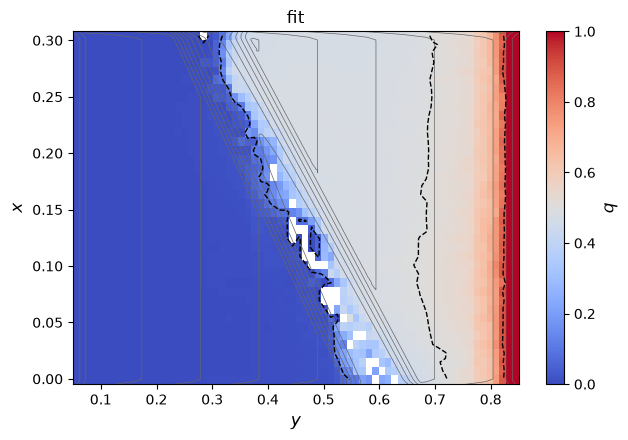

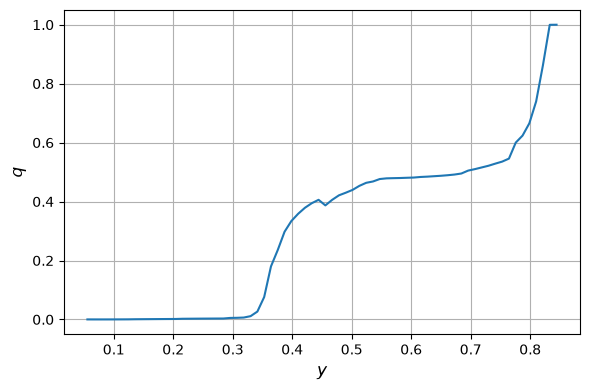

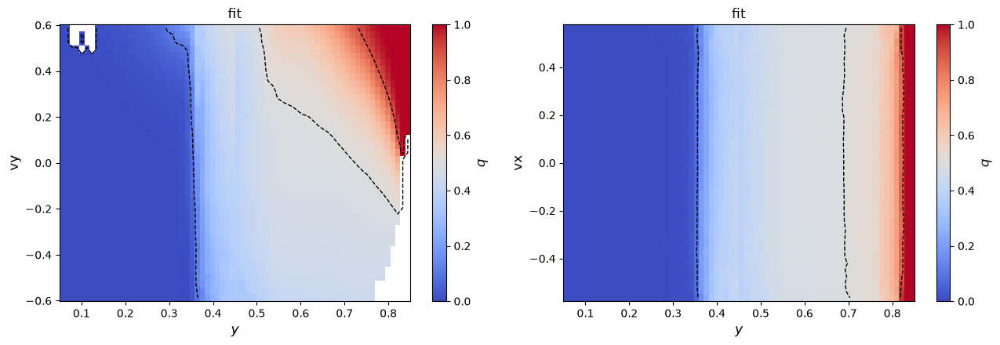

13500 iterations (main, envelope 0.01) | zqs_z 28.14
#=14000, dr2=397.727, zqs_z=27.795, sdzqs=102.015, |dx|=0.0128794, time=25.668
#=14500, dr2=384.564, zqs_z=25.4572, sdzqs=97.6514, |dx|=0.0110896, time=51.6279
#=15000, dr2=375.855, zqs_z=25.1144, sdzqs=93.7105, |dx|=0.0118009, time=77.5573
#=15500, dr2=365.242, zqs_z=23.3481, sdzqs=88.3657, |dx|=0.0100374, time=103.487
#=16000, dr2=356.177, zqs_z=22.9708, sdzqs=85.8391, |dx|=0.00956399, time=129.415
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it16000 ---


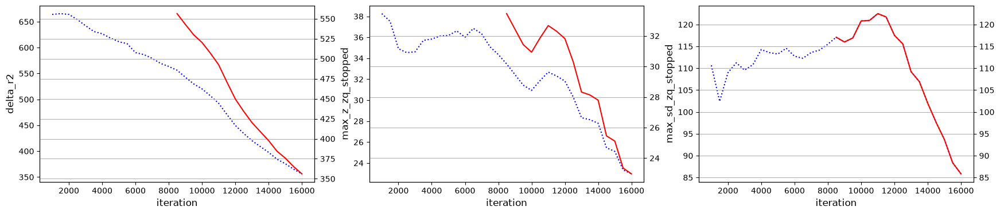

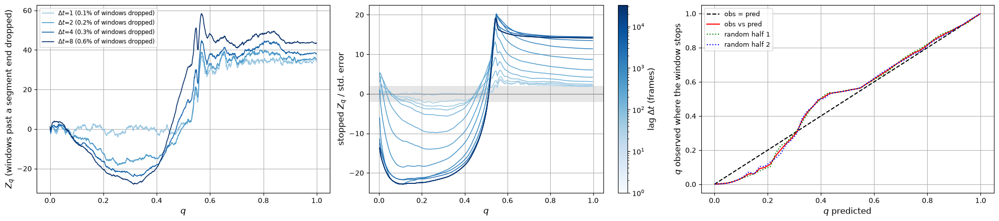

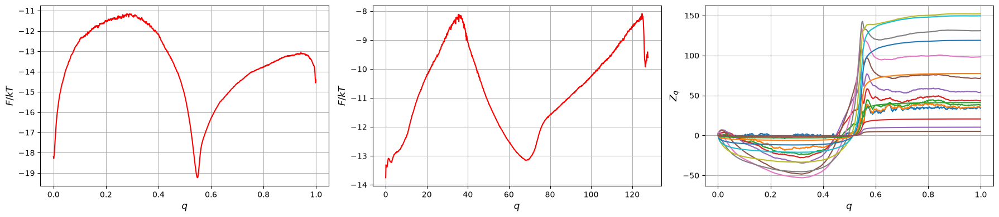

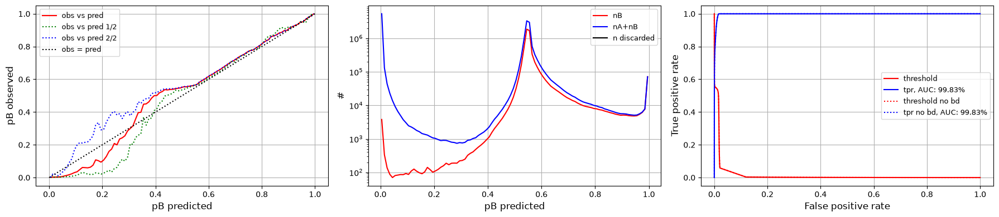

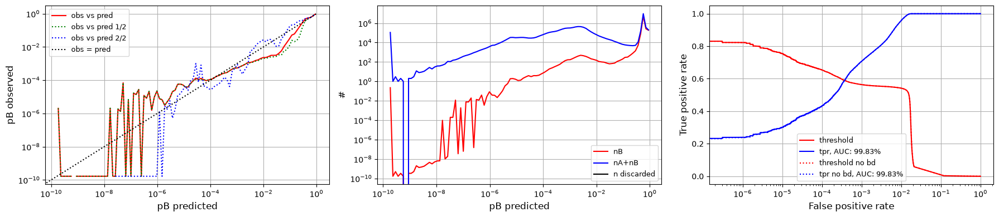

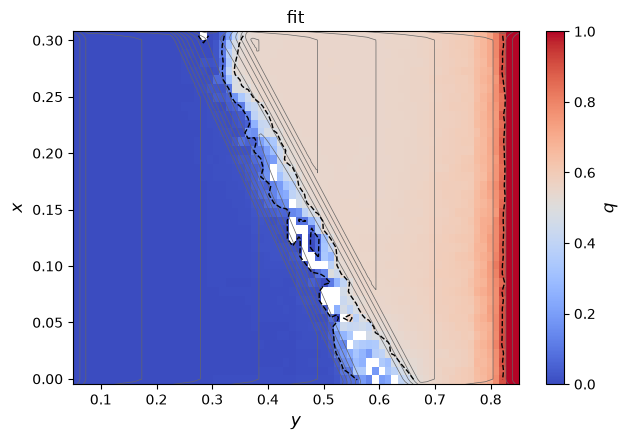

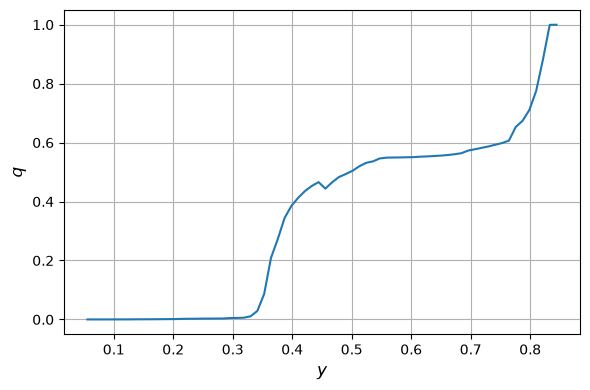

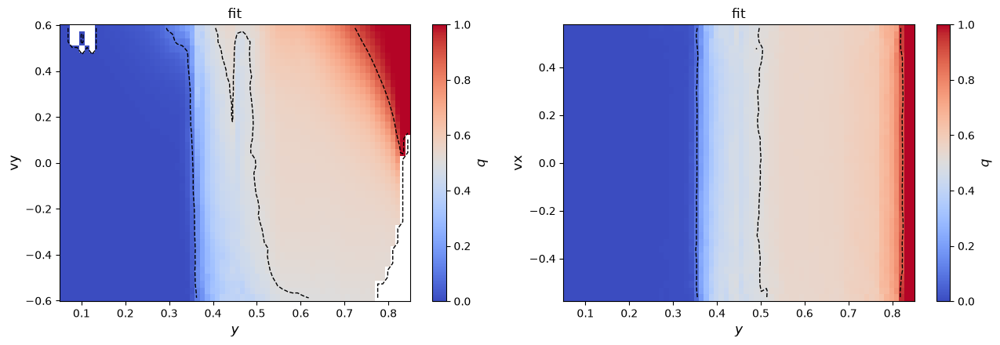

16000 iterations (main, envelope 0.01) | zqs_z 22.97
#=16500, dr2=342.202, zqs_z=22.5653, sdzqs=81.5753, |dx|=0.00978917, time=25.5858
#=17000, dr2=333.202, zqs_z=20.6553, sdzqs=79.1562, |dx|=0.00923954, time=51.5193
#=17500, dr2=322.859, zqs_z=19.3441, sdzqs=73.9531, |dx|=0.0085299, time=77.4313
#=18000, dr2=310.434, zqs_z=17.9875, sdzqs=70.0044, |dx|=0.00734502, time=103.377
#=18500, dr2=300.396, zqs_z=18.1151, sdzqs=66.0155, |dx|=0.00756461, time=129.279
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it18500 ---


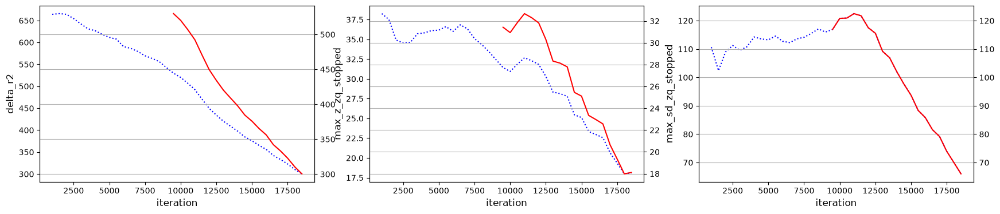

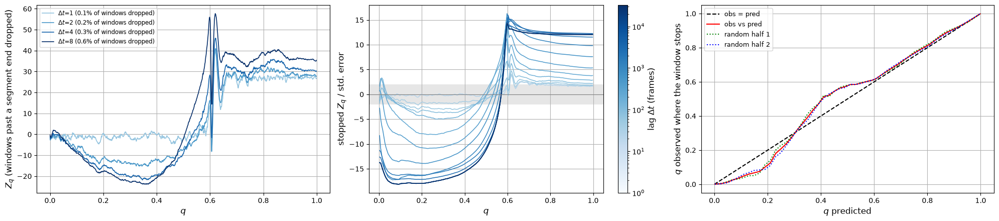

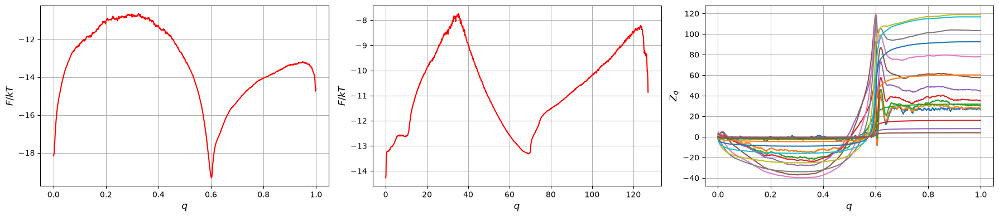

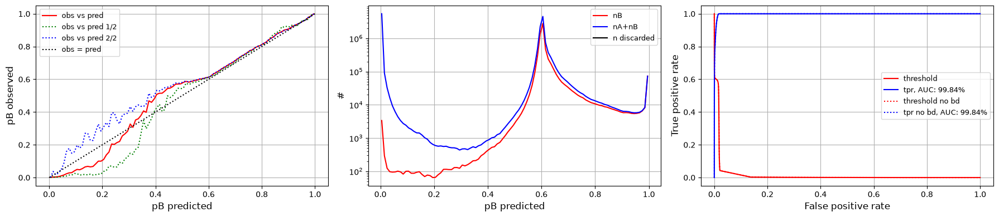

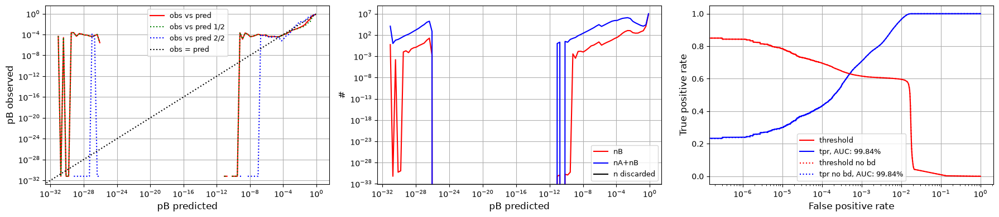

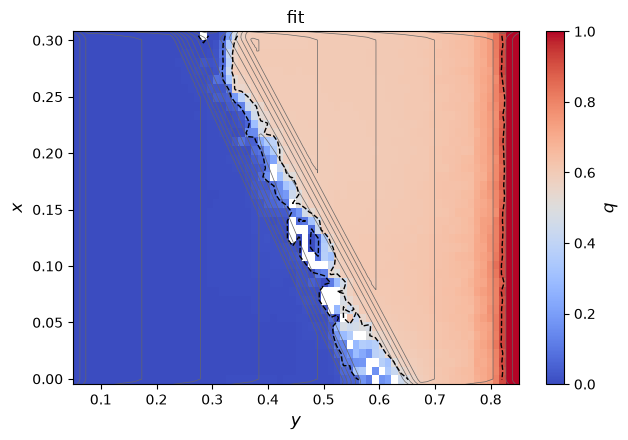

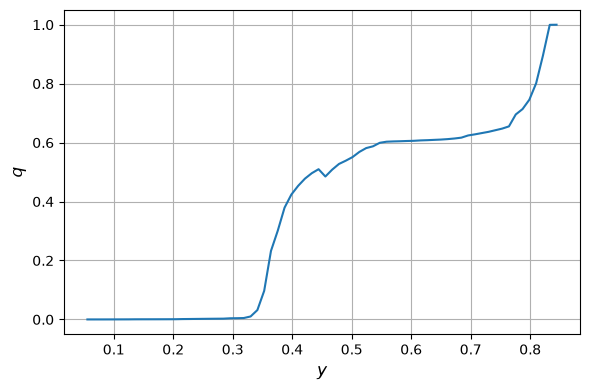

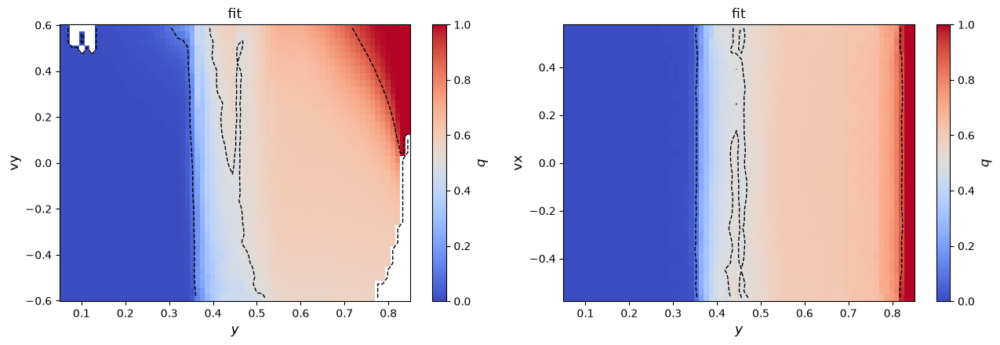

18500 iterations (main, envelope 0.01) | zqs_z 18.12
#=19000, dr2=290.515, zqs_z=17.8555, sdzqs=63.3703, |dx|=0.00801502, time=25.6015
#=19500, dr2=282.054, zqs_z=17.4764, sdzqs=58.6165, |dx|=0.00772585, time=51.5371
#=20000, dr2=273.416, zqs_z=16.407, sdzqs=56.9076, |dx|=0.00657813, time=77.5045
#=20500, dr2=264.319, zqs_z=15.851, sdzqs=53.4623, |dx|=0.0076145, time=103.341
#=21000, dr2=256.92, zqs_z=16.0122, sdzqs=49.9981, |dx|=0.00651212, time=129.311
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_zpot/langevin_g2/staple_sim_istarz_lgv_g2_vord/rev_none_p1000_s0_y-x-vy-vx_lag1_env0.01_g0.1_it20000_stopped/seed0/it21000 ---


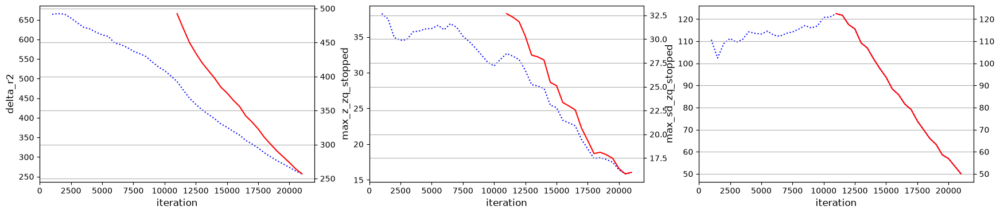

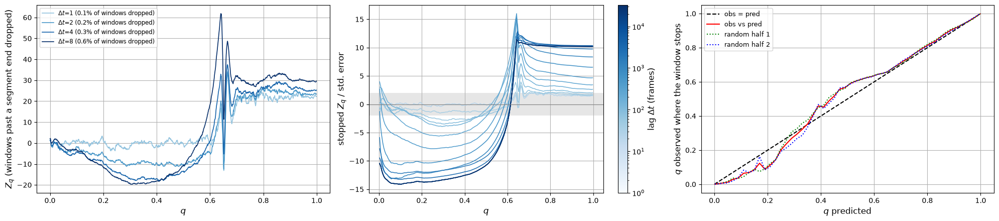

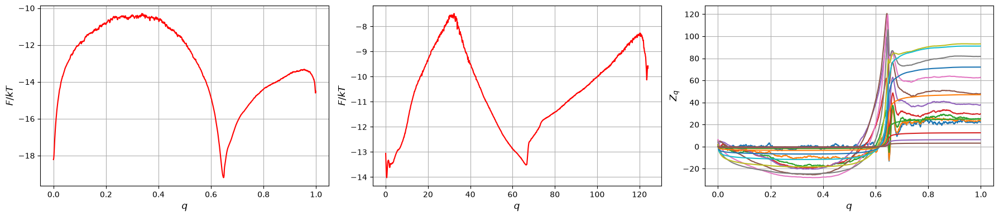

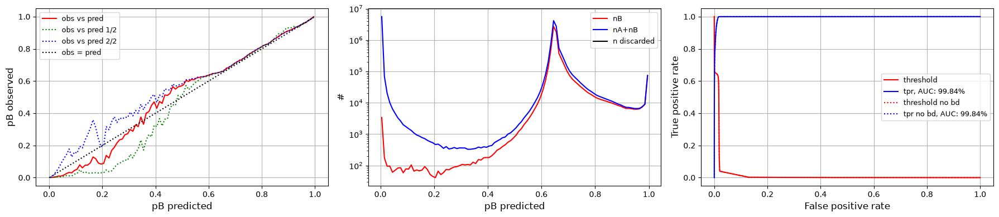

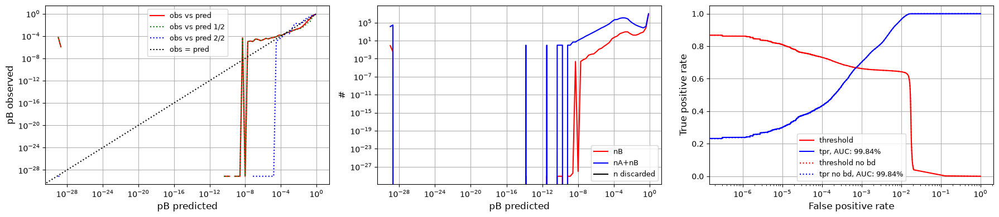

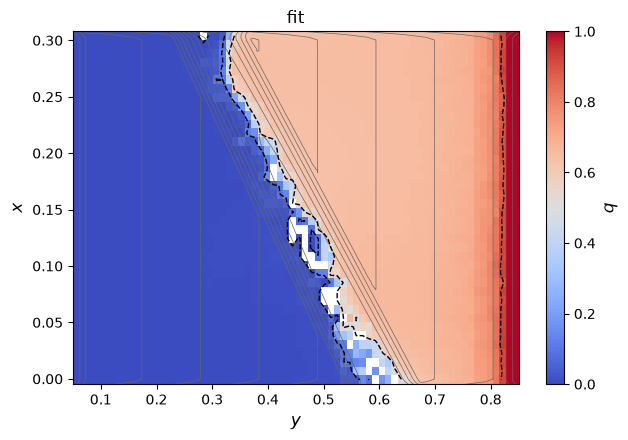

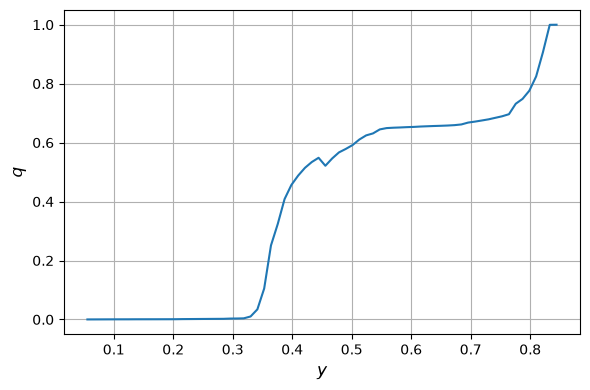

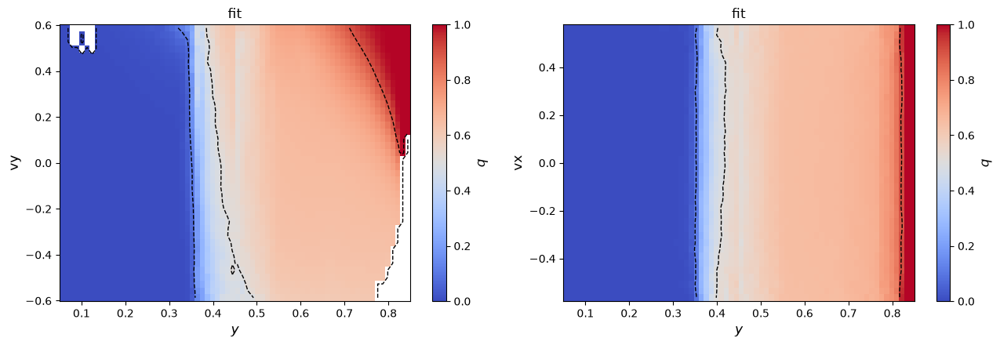

21000 iterations (main, envelope 0.01) | zqs_z 16.01


{'lazy_basis': True}

In [14]:
X_cv = cp.asarray(np.column_stack([cols[c] for c in CVS]))
e_y = np.linspace(LAMBDA_A, LAMBDA_B, 71)
e_x = np.linspace(*np.percentile(X[free], [0.5, 99.5]), 41)
planes = [seed_runs.plane(Y, e_y, '$y$', X, e_x, '$x$', CONTOURS)]
vel = [c for c in CVS if c in ('vy', 'vx', 'dy', 'dx')]
for c in vel:
    lim = np.percentile(np.abs(cols[c][free]), 99)
    planes.append(seed_runs.plane(Y, e_y, '$y$', cols[c], np.linspace(-lim, lim, 41), c))

# piece ends: in A or B (trap), or at a turn (stopped: windows past the end use q there)
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(Y) - 1]
stop_end = np.zeros(len(Y), bool)
stop_end[piece_end] = ~b[piece_end]
TRAP_LEN = max(2 ** 16, int(np.bincount(data.i_traj - data.i_traj.min()).max()) + 2 ** 15 + 1)   # Z_q lags go up to 2^15
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn, {len(piece_end) - stop_end.sum()} in A or B; A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x']
mid_y = (e_y[1:] + e_y[:-1]) / 2
prof_ref = None if q_exact is None else seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)(q_exact)
extras = {'q_map': seed_runs.committor_map(planes[:1], mask=free, q_ref=q_exact, min_count=MIN_COUNT),
          'q_profile': seed_runs.committor_profile(Y, e_y, '$y$', mask=free,
                                                   ref=None if prof_ref is None else (mid_y, prof_ref))}
if len(planes) > 1:
    extras['q_velocity_planes'] = seed_runs.committor_map(planes[1:], mask=free, min_count=MIN_COUNT)

def report(q):
    r = cp.asnumpy(q.r_traj)
    h = q.metrics_history.get('max_z_zq_stopped', [np.nan])
    out = f'| zqs_z {h[-1]:.2f}'
    if q_exact is not None:
        bm = seed_runs.BinnedMean(planes[0]['c'], planes[0]['edges'], free, MIN_COUNT)
        Qf, Qe = bm(r), bm(q_exact)
        t = (Qe > 0.05) & (Qe < 0.95)
        out += f' | RMS(fit - exact) per bin {np.sqrt(np.nanmean((Qf - Qe)[t] ** 2)):.4f}'
    if shoot_idx.size:
        out += f' | vs shooting {np.sqrt(np.nanmean((r[shoot_idx] - q_shoot) ** 2)):.4f}'
    return out

PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', 'obs_pred_log')     # saved and shown after every stage

def comp_y():
    """The CV of an iteration: one of the fit CVs, drawn at random."""
    return X_cv[:, np.random.randint(X_cv.shape[1])]

def show_stage(q, folder, n_done, stage):
    """Save and show the plots after a stage (FOLDER/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {report(q)}', flush=True)

fits = {}                                        # FIT_WEIGHTED entry -> r, tag, weights, results per seed
for weighted in FIT_WEIGHTED:
    W_fit = weights_for(weighted)                # 'none': every path once
    fit_tag = tag_for(weighted)
    fit_kw = dict(ny=NY, print_step=PRINT_STEP, save_min_metric='max_z_zq_stopped',
                  metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'),
                  **toy2d.lag_update(optimalrcs, data.i_traj, b, W_fit, FIT_LAG))   # the update of FIT_LAG
    results = {}
    for seed in FIT_SEEDS:
        print(f'===== fit, {label_of(weighted)}, seed {seed}: {fit_tag} =====')
        np.random.seed(seed)                     # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{FIG_DIR}/{fit_tag}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=A,                         # state A: q = 0
            boundary1=B,                         # state B: q = 1
            i_traj=data.i_traj,                  # piece of every frame
            t_traj=data.t_traj,                  # MD step of every frame
            path_weights=W_fit,                  # MC weight of the frame's path
            group_traj=data.group_traj,          # path of every frame: its forward and mirrored piece are one unit
        )
        q.set_fixed_traj_length_trap(b, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)     # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=FIT_GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}')

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=FIT_GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}')

        r = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
        results[seed] = dict(r=r, report=report(q))
        del q                                    # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[weighted] = dict(r=results[FIT_SEEDS[-1]]['r'], tag=fit_tag, W=W_fit, results=results)

# the first fit is the main one (used by section 9)
r, fit_tag, results = fits[FIT_WEIGHTED[0]]['r'], fits[FIT_WEIGHTED[0]]['tag'], fits[FIT_WEIGHTED[0]]['results']
q = types.SimpleNamespace(r_traj=cp.asarray(r))
toy2d.lag_update(optimalrcs, data.i_traj, b, weights_for(FIT_WEIGHTED[0]), FIT_LAG)


## 7. Results

For every fit of `FIT_WEIGHTED` (the stopped z of the exact committor is shown with the same weighting):

- The worst stopped z per lag of the fit (and of the exact committor on the same data).
- q against the order parameter: every frame (sample) and the weighted mean per bin, with the exact committor.
- Maps: fit, exact and fit − exact on (y, x); for velocity CVs the fit on (y, v).
- Isocommittor lines of the fit (and the exact committor) on the potential.
- Fit against the shooting reference, and against the MD committor of `toy2d_md.ipynb` if given.
- Seeds: the fits of all `FIT_SEEDS` against each other (if more than one).

In [ ]:
for weighted in FIT_WEIGHTED:
    r, fit_tag, W_fit, results = (fits[weighted][k] for k in ('r', 'tag', 'W', 'results'))
    q_view = types.SimpleNamespace(r_traj=r)
    label = label_of(weighted)
    print(f'===== fit {label}: {fit_tag} =====')
    z_fit = toy2d.z_per_lag(r, b, data.i_traj, W_fit, LAGS, data.group_traj)
    fits[weighted]['z'] = z_fit
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(LAGS, z_fit, 'o-', label='fit')
    if q_exact is not None:
        ax.plot(LAGS, z_exact[weighted], 's--', label='exact committor')
    ax.axhline(2, color='k', ls=':')
    if FIT_LAG > 1:
        ax.axvline(FIT_LAG, color='C3', lw=0.8, label=f'fit lag {FIT_LAG}')
    ax.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title=f'stopped Z_q test per lag (own data, {label})')
    ax.legend()
    ax.grid(alpha=0.3)
    save_fig(f'z_per_lag_{fit_tag}')
    plt.show()
    print('worst |z| per lag', LAGS, ':', ' '.join(f'{z:.1f}' for z in z_fit))

    fig, ax = plt.subplots(figsize=(11, 4.5))
    show = np.random.default_rng(0).choice(len(r), size=min(200_000, len(r)), replace=False)
    ax.scatter(Y[show], r[show], s=1, alpha=0.15, edgecolors='none', label='frames')
    bmw = seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)
    ax.plot(mid_y, bmw(W_fit * r) / bmw(W_fit), 'C3', lw=2, label='weighted mean per bin')
    if prof_ref is not None:
        ax.plot(mid_y, bmw(W_fit * q_exact) / bmw(W_fit), 'k--', lw=1.5, label='exact, same frames')
    for lam in INTFS:
        ax.axvline(lam, color='k', lw=0.5, ls=':')
    ax.set(xlabel='$y$', ylabel='$q$')
    ax.legend()
    save_fig(f'q_vs_order_{fit_tag}')
    plt.show()

    fig = seed_runs.committor_map(planes[:1], mask=free, q_ref=q_exact, min_count=MIN_COUNT)(q_view)
    save_fig(f'result_map_{fit_tag}', fig)
    plt.show()
    if len(planes) > 1:
        fig = seed_runs.committor_map(planes[1:], mask=free, min_count=MIN_COUNT)(q_view)
        save_fig(f'result_velocity_planes_{fit_tag}', fig)
        plt.show()

    p = planes[0]
    bm5 = seed_runs.BinnedMean(p['c'], p['edges'], free, 5)
    (e1, e2) = p['edges']
    m1, m2 = (e1[1:] + e1[:-1]) / 2, (e2[1:] + e2[:-1]) / 2
    levels = [0.1, 0.25, 0.5, 0.75, 0.9]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    draw_potential(ax)
    cs = ax.contour(m1, m2, bm5(r).T, levels=levels, colors='C3', linewidths=1.8)
    ax.clabel(cs, fmt='%.2f', fontsize=8)
    ax.plot([], [], 'C3', label='fit (mean per bin)')
    if ref is not None:
        ax.contour(ref['y'], ref['x'], ref['q'].T, levels=levels, colors='C0', linewidths=1.2, linestyles='--')
        ax.plot([], [], 'C0--', label='exact')
    ax.legend()
    ax.set_title('isocommittor lines 0.1, 0.25, 0.5, 0.75, 0.9 (grey: $V/kT$ = 0, 1, 2, ...)')
    save_fig(f'isocommittor_{fit_tag}')
    plt.show()

    if shoot_idx.size:
        d = r[shoot_idx] - q_shoot
        fig, ax = plt.subplots(figsize=(5.5, 5))
        ax.errorbar(q_shoot, r[shoot_idx], xerr=se_shoot, fmt='.', ms=3, alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel='shooting', ylabel='fit',
               title=f'fit vs shooting at {len(shoot_idx)} frames: RMS {np.sqrt(np.nanmean(d ** 2)):.3f}\n'
                     f'mean {np.nanmean(d):+.4f} (shooting error {np.nanmean(se_shoot):.3f})')
        save_fig(f'fit_vs_shooting_{fit_tag}')
        plt.show()

    if md_ref is not None:
        # the MD fit, binned on the same (y, x) bins as this fit (mean over the MD frames vs over the path frames)
        bm_md = seed_runs.BinnedMean((md_ref['y'], md_ref['x']), p['edges'], None, MIN_COUNT)
        bm_pf = seed_runs.BinnedMean(p['c'], p['edges'], free, MIN_COUNT)
        Qm, Qp = bm_md(md_ref['q_fit']), bm_pf(r)
        fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
        for ax, (M, title, cmap, lim) in zip(axes, [(Qp, 'staple fit', 'coolwarm', (0, 1)), (Qm, 'MD fit', 'coolwarm', (0, 1)),
                                                   (Qp - Qm, 'staple $-$ MD (bin means)', 'PuOr', (-0.15, 0.15))]):
            im = ax.pcolormesh(e1, e2, M.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
            ax.set(title=title, xlabel='$y$', ylabel='$x$')
            fig.colorbar(im, ax=ax)
        fig.suptitle('Note: for Langevin dynamics the bin means average over different velocity distributions')
        fig.tight_layout()
        save_fig(f'staple_vs_md_{fit_tag}', fig)
        plt.show()

    if len(results) > 1:
        seeds = list(results)
        fig, ax = plt.subplots(figsize=(5.5, 5))
        for s in seeds[1:]:
            ax.plot(results[seeds[0]]['r'][free][::200], results[s]['r'][free][::200], '.', ms=2, label=f'seed {s}')
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel=f'seed {seeds[0]}', ylabel='other seeds', title='fits with different seeds (every 200th frame)')
        ax.legend()
        save_fig(f'seeds_{fit_tag}')
        plt.show()
r, fit_tag, results = fits[FIT_WEIGHTED[0]]['r'], fits[FIT_WEIGHTED[0]]['tag'], fits[FIT_WEIGHTED[0]]['results']


## 7b. With and Without Weights

The fits of `FIT_WEIGHTED` side by side, on the same frames:

- the worst stopped z per lag of each fit and of the exact committor, each with the weighting of its fit (the exact committor tests the data: it should pass with the right weights);
- the mean q per bin of the order parameter (weighted by the MC weights in both cases, so the curves compare the fits, not the averaging) with the exact committor;
- on (y, x): each fit − exact, and with weights − without weights;
- a table: RMS against the exact committor per bin (0.05 < q < 0.95), RMS and mean difference against shooting, worst z.


In [ ]:
if len(fits) < 2:
    print('only one fit in FIT_WEIGHTED: nothing to compare')
else:
    names = {w: label_of(w) for w in FIT_WEIGHTED}
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for k, weighted in enumerate(FIT_WEIGHTED):
        ax.plot(LAGS, fits[weighted]['z'], 'o-', color=f'C{k}', label=f'fit {names[weighted]}')
        if q_exact is not None:
            ax.plot(LAGS, z_exact[weighted], 's--', color=f'C{k}', alpha=0.6, label=f'exact, {names[weighted]}')
    ax.axhline(2, color='k', ls=':')
    ax.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title='stopped Z_q test per lag')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    save_fig(f'weights_z_per_lag_{tag_for(FIT_WEIGHTED[0])}')
    plt.show()

    bmw = seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for k, weighted in enumerate(FIT_WEIGHTED):
        ax.plot(mid_y, bmw(W * fits[weighted]['r']) / bmw(W), color=f'C{k}', lw=2, label=f'fit {names[weighted]}')
    if q_exact is not None:
        ax.plot(mid_y, bmw(W * q_exact) / bmw(W), 'k--', lw=1.5, label='exact')
    for lam in INTFS:
        ax.axvline(lam, color='k', lw=0.5, ls=':')
    ax.set(xlabel='$y$', ylabel='$q$ (MC-weighted mean per bin)')
    ax.legend()
    save_fig(f'weights_q_vs_order_{tag_for(FIT_WEIGHTED[0])}')
    plt.show()

    p = planes[0]
    bm = seed_runs.BinnedMean(p['c'], p['edges'], free, MIN_COUNT)
    (e1, e2) = p['edges']
    Q = {w: bm(fits[w]['r']) for w in FIT_WEIGHTED}
    panels = []
    if q_exact is not None:
        Qe = bm(q_exact)
        trans = (Qe > 0.05) & (Qe < 0.95)
        panels += [(Q[w] - Qe, f'fit {names[w]} $-$ exact, RMS {np.sqrt(np.nanmean((Q[w] - Qe)[trans] ** 2)):.4f}') for w in FIT_WEIGHTED]
    panels.append((Q[FIT_WEIGHTED[0]] - Q[FIT_WEIGHTED[1]], f'{names[FIT_WEIGHTED[0]]} $-$ {names[FIT_WEIGHTED[1]]}'))
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 4.5), squeeze=False)
    for ax, (M, title) in zip(axes[0], panels):
        im = ax.pcolormesh(e1, e2, M.T, cmap='PuOr', vmin=-0.15, vmax=0.15)
        g1, g2, Vc, lev = CONTOURS
        ax.contour(g1, g2, Vc.T, levels=lev, colors='0.4', linewidths=0.5)
        ax.set(title=title, xlabel='$y$', ylabel='$x$', xlim=(e1[0], e1[-1]), ylim=(e2[0], e2[-1]))
        fig.colorbar(im, ax=ax)
    fig.tight_layout()
    save_fig(f'weights_maps_{tag_for(FIT_WEIGHTED[0])}', fig)
    plt.show()

    print(f'{"fit":24s} {"RMS vs exact":>13s} {"RMS vs shoot":>13s} {"mean - shoot":>13s}   worst |z| at lags {LAGS}')
    for w in FIT_WEIGHTED:
        rr = fits[w]['r']
        rms_ex = np.sqrt(np.nanmean((Q[w] - Qe)[trans] ** 2)) if q_exact is not None else np.nan
        rms_sh = np.sqrt(np.nanmean((rr[shoot_idx] - q_shoot) ** 2)) if shoot_idx.size else np.nan
        mean_sh = np.nanmean(rr[shoot_idx] - q_shoot) if shoot_idx.size else np.nan
        print(f'{names[w]:24s} {rms_ex:13.4f} {rms_sh:13.4f} {mean_sh:+13.4f}   ' + ' '.join(f'{z:.1f}' for z in fits[w]['z']))
    if q_exact is not None:
        for w in FIT_WEIGHTED:
            print(f'{"exact, " + names[w]:24s} {"":13s} {"":13s} {"":13s}   ' + ' '.join(f'{z:.1f}' for z in z_exact[w]))


## 7c. Position Histories Instead of Velocities

The velocity fit above uses (y, x, v_y, v_x) as CVs. Here the fit sees positions only, and the velocity information comes from the history, as in `base_documented_2d_langevin.ipynb`: every iteration draws a position c (y or x) and a lag d from `HIST_DELTA`; d = 0 gives a basis in (q(t), c(t)), d = 1 a basis in (c(t − 1), c(t)), which carries that coordinate's velocity (`history_type = ['y(t-d),y(t)']`). The update is the library's lag-1 step. In mirrored pieces t − 1 is the later frame, so the history is that of the reversed dynamics, consistent with the pieces.

Same committor setup (weights of `HIST_WEIGHTED`, traps, stopped ends) and plots as in section 6, saved under a `..._hist01_...` tag. Then the history fit against the velocity fit of the same weights: RMS against shooting, the worst stopped z per lag, and q on the (y, v) planes (the recorded or finite-difference velocities are used only for these plots).


In [ ]:
# Fit with position histories (d = 0, 1) instead of velocities as CVs
HIST_CVS = ('y', 'x')                    # positions only: the velocity information comes from the history
HIST_DELTA = [0, 1]                      # lag d drawn per iteration: 0 -> (q(t), c(t)), 1 -> (c(t-1), c(t))
HIST_WEIGHTED = FIT_WEIGHTED[0]          # weights of the history fit (a FIT_WEIGHTED-style entry)
HIST_SEED = FIT_SEEDS[0]

H_cv = cp.asarray(np.column_stack([cols[c] for c in HIST_CVS]))
W_hist = weights_for(HIST_WEIGHTED)
hist_tag = (f'{"rev" if REVERSED else "fwd"}_{scheme_of(HIST_WEIGHTED)}_p{PATHS_PER_ENSEMBLE}_s{PATH_SEED}'
            + f'_{"-".join(HIST_CVS)}_hist{"".join(map(str, HIST_DELTA))}_lag1_env{ENVELOPE:g}_g{FIT_GAMMA:g}_it{MAX_ITER}'
            + ('_stopped' if STOPPED_ENDS else ''))
folder = f'{FIG_DIR}/{hist_tag}/seed{HIST_SEED}'
hist_fit_kw = dict(ny=NY, print_step=PRINT_STEP, save_min_metric='max_z_zq_stopped',
                   metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'),
                   history_delta_t=HIST_DELTA,                 # lags drawn per iteration
                   history_type=['y(t-d),y(t)'],               # basis in (c(t-d), c(t)) for d > 0
                   history_shift_type='r(t)',
                   **toy2d.lag_update(optimalrcs, data.i_traj, b, W_hist, 1))   # the library's lag-1 update

def hist_comp_y():
    """The position of an iteration: y or x, drawn at random."""
    return H_cv[:, np.random.randint(H_cv.shape[1])]

print(f'===== history fit, {label_of(HIST_WEIGHTED)}, seed {HIST_SEED}: {hist_tag} =====')
np.random.seed(HIST_SEED)
cp.random.seed(HIST_SEED)
q_h = optimalrcs.CommittorNE(
    boundary0=A,                         # state A: q = 0
    boundary1=B,                         # state B: q = 1
    i_traj=data.i_traj,                  # piece of every frame
    t_traj=data.t_traj,                  # MD step of every frame
    path_weights=W_hist,                 # MC weight of the frame's path
    group_traj=data.group_traj,          # path of every frame: its forward and mirrored piece are one unit
)
q_h.set_fixed_traj_length_trap(b, TRAP_LEN if STOPPED_ENDS else 2 ** 16)
if STOPPED_ENDS:
    q_h.set_stopped_traj_end(stop_end)

n_done = 0
if WARMUP_ITER:                          # warm-up with a wide envelope
    optimalrcs.envelope_scale = WARMUP_ENVELOPE
    q_h.fit_transform(hist_comp_y, gamma=FIT_GAMMA, max_iter=WARMUP_ITER, **hist_fit_kw)
    n_done += WARMUP_ITER
    show_stage(q_h, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}')
optimalrcs.envelope_scale = ENVELOPE     # main fit, in chunks of CHUNK iterations
while n_done < WARMUP_ITER + MAX_ITER:
    n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
    q_h.fit_transform(hist_comp_y, gamma=FIT_GAMMA, max_iter=n_iter, **hist_fit_kw)
    n_done += n_iter
    show_stage(q_h, folder, n_done, f'main, envelope {ENVELOPE}')

r_hist = cp.asnumpy(q_h.r_traj)
np.save(f'{folder}/q_traj.npy', r_hist.astype(np.float32))
del q_h
cp.get_default_memory_pool().free_all_blocks()
toy2d.lag_update(optimalrcs, data.i_traj, b, weights_for(FIT_WEIGHTED[0]), FIT_LAG)   # the velocity fits' update back

# history fit against the velocity fit of the same weights
z_hist = toy2d.z_per_lag(r_hist, b, data.i_traj, W_hist, LAGS, data.group_traj)
rows = {f'history ({"-".join(HIST_CVS)}, d = {HIST_DELTA})': (r_hist, z_hist)}
if HIST_WEIGHTED in fits:
    rows[f'velocities ({"-".join(CVS)}, lag {FIT_LAG})'] = (fits[HIST_WEIGHTED]['r'], fits[HIST_WEIGHTED]['z'])
print(f'{label_of(HIST_WEIGHTED)}:')
print(f'{"fit":36s} {"RMS vs shoot":>13s} {"mean - shoot":>13s}   worst |z| at lags {LAGS}')
for name, (rr, zz) in rows.items():
    rms_sh = np.sqrt(np.nanmean((rr[shoot_idx] - q_shoot) ** 2)) if shoot_idx.size else np.nan
    mean_sh = np.nanmean(rr[shoot_idx] - q_shoot) if shoot_idx.size else np.nan
    print(f'{name:36s} {rms_sh:13.4f} {mean_sh:+13.4f}   ' + ' '.join(f'{z:.1f}' for z in zz))

fig, ax = plt.subplots(figsize=(7, 4.2))
for k, (name, (rr, zz)) in enumerate(rows.items()):
    ax.plot(LAGS, zz, 'o-', color=f'C{k}', label=name)
ax.axhline(2, color='k', ls=':')
ax.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title=f'history vs velocity CVs ({label_of(HIST_WEIGHTED)})')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
save_fig(f'hist_vs_velocity_z_{hist_tag}')
plt.show()

if shoot_idx.size:
    fig, axes = plt.subplots(1, len(rows), figsize=(5.5 * len(rows), 5), squeeze=False)
    for ax, (name, (rr, zz)) in zip(axes[0], rows.items()):
        d = rr[shoot_idx] - q_shoot
        ax.errorbar(q_shoot, rr[shoot_idx], xerr=se_shoot, fmt='.', ms=3, alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel='shooting', ylabel='fit', title=f'{name}\nRMS {np.sqrt(np.nanmean(d ** 2)):.3f}')
    fig.tight_layout()
    save_fig(f'hist_vs_velocity_shooting_{hist_tag}', fig)
    plt.show()

fig = seed_runs.committor_map(planes, mask=free, min_count=MIN_COUNT)(types.SimpleNamespace(r_traj=r_hist))
fig.suptitle('history fit: mean q per bin (velocities: plots only)', y=1.02)
save_fig(f'hist_planes_{hist_tag}', fig)
plt.show()


## 8. Save

The fitted q per frame with the frames, pieces, weights and references, as `FIG_DIR/committor_<fit tag>.npz`, one file per fit of `FIT_WEIGHTED` (`path_weights`: the weights the fit used; `weights_used`: their scheme).

In [ ]:
for weighted in FIT_WEIGHTED:
    fit = fits[weighted]
    W_fit_saved = fit['W']
    out = f'{FIG_DIR}/committor_{fit["tag"]}.npz'
    np.savez(out, q_fit=fit['r'].astype(np.float32), X_all=data.X_all.astype(np.float32), i_traj=data.i_traj,
             group_traj=data.group_traj, t_traj=data.t_traj, path_weights=W_fit_saved, weights_used=scheme_of(weighted), boundary0=A, boundary1=B,
             q_exact=(q_exact if q_exact is not None else np.full(len(fit['r']), np.nan)).astype(np.float32),
             shoot_idx=shoot_idx, q_shoot=q_shoot if shoot_idx.size else [], z_fit=fit['z'], lags=LAGS,
             settings=repr(dict(run=RUN, cvs=CVS, fit_lag=FIT_LAG, reversed=REVERSED, weights=scheme_of(weighted),
                                stopped_ends=STOPPED_ENDS, paths_per_ensemble=PATHS_PER_ENSEMBLE, path_seed=PATH_SEED,
                                max_length=MAX_LENGTH, envelope=ENVELOPE, fit_gamma=FIT_GAMMA, ny=NY, max_iter=MAX_ITER,
                                warmup=WARMUP_ITER, seeds=FIT_SEEDS)))
    print('saved', out)


## 9. Fit on New Fixed-Length Trajectories from Random Path Frames

A second, independent data set (the PI's validation): `FT_N_POINTS` random frames of the path data (uniform over the frames outside A and B, or with `FT_START = 'q_bins'` equal numbers in 10 bins of the path-data fit: the path frames crowd near the interfaces and, on the 2D Z, on the plateau), one new trajectory of the run's dynamics from each (`toy2d.Integrator`), `FT_LENGTH` steps long or shorter if it reaches A or B (absorption checked every step, as in the run). Compared with the first fit of `FIT_WEIGHTED`. NPNEq is fitted on these trajectories with the same CVs, fit lag and fit settings as the path data, without weights.

- The new trajectories are plain dynamics: no path selection, no cut at M, no mirrored pieces, no MC weights. A fit on them is unbiased whatever the start distribution, so it tests what the path-data preparation and weights may have introduced.
- Langevin trajectories start with the frame's recorded velocity (needed, as for shooting). `dy`/`dx` CVs are the change over the last step / dt (at the start frame: the data's value).
- Compared at the start frames (each is a frame of both data sets): the new fit against the path-data fit, and both against the exact committor (Brownian runs). Also the stopped Z_q test per lag on the new data, and the maps.
- **Limits:** like the path data, trajectories of length L fix the level of q only through the ones that reach A or B (printed as the absorbed fraction). A region the trajectories do not leave within L (a plateau) has its level set only by the smoothness of the fit, as for the staple pieces. Make L longer to test levels.
- Cost: `FT_N_POINTS` × L frames (10k × the median piece length is a few million frames, a fraction of the path data).

In [ ]:
# New data: fixed-length trajectories from random path frames, and an NPNEq fit on them
import types
FT_N_POINTS = 10_000      # random start frames (uniform over the free frames of the path data)
FT_LENGTH = None          # steps per trajectory; None: the median piece length
FT_START = 'uniform'      # 'uniform': random free frames; 'q_bins': equal numbers in 10 bins of the path-data fit
FT_SEED = 0
FT_MAX_ITER, FT_CHUNK = MAX_ITER, CHUNK          # fit settings; the rest as for the path data

if not (hasattr(pot, 'potential_and_force_xy') and (BROWNIAN or V_ORD)):
    raise RuntimeError('new trajectories need a vectorized potential, and recorded velocities for Langevin runs '
                       '(everything above, including the saved fits, is complete)')
r_path = cp.asnumpy(q.r_traj)                    # the path-data fit (q is reused below)

# 1. start frames and trajectories (all at once on the GPU; a trajectory stops when it reaches A or B)
rng = np.random.default_rng(FT_SEED)
if FT_START == 'uniform':
    start = np.sort(rng.choice(np.flatnonzero(free), size=FT_N_POINTS, replace=False))
else:                                            # the path frames crowd near the interfaces and on plateaus
    q_bin = np.clip((r_path * 10).astype(int), 0, 9)
    start = np.sort(np.concatenate([rng.choice(np.flatnonzero(free & (q_bin == k)), replace=False,
                                               size=min(FT_N_POINTS // 10, np.sum(free & (q_bin == k))))
                                    for k in range(10)]))
FT_N_POINTS = len(start)
L = FT_LENGTH or int(np.median(lengths))
engine = toy2d.Integrator(pot, DT, KT, GAMMA, MASS, BROWNIAN, xp=cp, seed=FT_SEED)
y, x = cp.asarray(Y[start]), cp.asarray(X[start])
vy = cp.asarray(cols['vy'][start]) if V_ORD else cp.zeros(FT_N_POINTS)
vx = cp.asarray(cols['vx'][start]) if V_ORD else cp.zeros(FT_N_POINTS)
frames = {c: cp.zeros((L + 1, FT_N_POINTS)) for c in ('y', 'x', 'vy', 'vx')}    # frames[c][step, trajectory]
for c, v in zip(('y', 'x', 'vy', 'vx'), (y, x, vy, vx)):
    frames[c][0] = v
last = cp.full(FT_N_POINTS, L)                   # last frame of each trajectory
running = cp.ones(FT_N_POINTS, bool)
t0 = time.time()
for step in range(1, L + 1):
    y, x, vy, vx = engine.step(y, x, vy, vx)
    for c, v in zip(('y', 'x', 'vy', 'vx'), (y, x, vy, vx)):
        frames[c][step] = v
    hit = running & ((y <= LAMBDA_A) | (y >= LAMBDA_B))
    last = cp.where(hit, step, last)
    running &= ~hit
print(f'{FT_N_POINTS} trajectories of up to {L} steps in {time.time() - t0:.0f} s; '
      f'{float(1 - running.mean()):.0%} reached A or B')

# 2. flatten to the fit's format: one segment per trajectory, frames 0 .. last
last = cp.asnumpy(last)
keep = (np.arange(L + 1)[:, None] <= last[None, :]).T                 # [trajectory, step]
ft = {c: cp.asnumpy(v).T[keep] for c, v in frames.items()}
del frames
ft_i = np.repeat(np.arange(FT_N_POINTS), last + 1)
ft_t = np.concatenate([np.arange(n + 1) for n in last]).astype(float)
ft_first = np.r_[0, np.cumsum(last + 1)[:-1]]                         # index of each start frame
ft_A, ft_B = ft['y'] <= LAMBDA_A, ft['y'] >= LAMBDA_B
ft_b = ft_A | ft_B
ft_free = ~ft_b
step_back = np.where(ft_t > 0, np.arange(len(ft_t)) - 1, np.arange(len(ft_t)))
ft_cols = {'y': ft['y'], 'x': ft['x'], 'vy': ft['vy'], 'vx': ft['vx'],
           'dy': (ft['y'] - ft['y'][step_back]) / DT, 'dx': (ft['x'] - ft['x'][step_back]) / DT}
for c in ('dy', 'dx'):                           # the start frame keeps the data's finite difference
    if c in cols:
        ft_cols[c][ft_first] = cols[c][start]
ft_q_exact = None
if ref is not None:
    ft_q_exact = toy2d.interp_grid(ref, ft['y'], ft['x'])
    ft_q_exact[ft_A], ft_q_exact[ft_B] = 0.0, 1.0
print(f'{len(ft_t):,} frames; {ft_A.sum()} in A, {ft_B.sum()} in B')

# 3. NPNEq fit on the new trajectories: same CVs, lag and settings, no weights
ft_X_cv = cp.asarray(np.column_stack([ft_cols[c] for c in CVS]))
ft_fit_kw = dict(ny=NY, print_step=PRINT_STEP, save_min_metric='max_z_zq_stopped',
                 metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'),
                 **toy2d.lag_update(optimalrcs, ft_i, ft_b, None, FIT_LAG))
ft_plane = seed_runs.plane(ft['y'], e_y, '$y$', ft['x'], e_x, '$x$', CONTOURS)
ft_extras = {'q_map': seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact, min_count=MIN_COUNT)}
ft_folder = f'{FIG_DIR}/{fit_tag}_newtraj_n{FT_N_POINTS}_L{L}/seed{FT_SEED}'
np.random.seed(FT_SEED)
cp.random.seed(FT_SEED)
ft_comp_y = lambda: ft_X_cv[:, np.random.randint(ft_X_cv.shape[1])]

q_ft = optimalrcs.CommittorNE(boundary0=ft_A, boundary1=ft_B, i_traj=ft_i, t_traj=ft_t)   # one segment per trajectory
q_ft.set_fixed_traj_length_trap(ft_b, 2 ** 16)   # trajectories end in A/B or after L steps (a fixed length)
n_done = 0
for n_iter, env, stage in [(WARMUP_ITER, WARMUP_ENVELOPE, 'warm-up')] + [(FT_CHUNK, ENVELOPE, 'main')] * (FT_MAX_ITER // FT_CHUNK):
    if n_iter == 0:
        continue
    optimalrcs.envelope_scale = env
    q_ft.fit_transform(ft_comp_y, gamma=FIT_GAMMA, max_iter=n_iter, **ft_fit_kw)
    n_done += n_iter
    seed_runs.save_and_show(q_ft, ft_folder, f'it{n_done}', ('metrics', 'tis', 'feps'), dict(metrics=METRICS), ft_extras)
    print(f'new-trajectory fit: {n_done} iterations ({stage}, envelope {env})', flush=True)
r_ft = cp.asnumpy(q_ft.r_traj)
del ft_X_cv, q_ft
cp.get_default_memory_pool().free_all_blocks()
toy2d.lag_update(optimalrcs, data.i_traj, b, W, FIT_LAG)              # the path data's update back in place

# 4. comparison at the start frames, and the stopped Z_q test on the new data
z_ft = toy2d.z_per_lag(r_ft, ft_b, ft_i, None, LAGS)
print('new data, new fit: worst |stopped z| at lags', LAGS, ':', ' '.join(f'{z:.1f}' for z in z_ft))
at_start = {'new-trajectory fit': r_ft[ft_first], 'path-data fit': r_path[start]}
if q_exact is not None:
    at_start['exact'] = q_exact[start]
names = list(at_start)
for i, a in enumerate(names):
    for c in names[i + 1:]:
        d = at_start[a] - at_start[c]
        print(f'at the {FT_N_POINTS} start frames: {a} - {c}: mean {d.mean():+.4f}, RMS {np.sqrt(np.mean(d ** 2)):.4f}')
q_bins = np.linspace(0, 1, 21)
q_mid = (q_bins[1:] + q_bins[:-1]) / 2
ref_name = 'exact' if q_exact is not None else 'path-data fit'
k = np.clip(np.digitize(at_start[ref_name], q_bins) - 1, 0, len(q_mid) - 1)
cnt = np.bincount(k, minlength=len(q_mid))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))
ax1.plot(at_start['path-data fit'], at_start['new-trajectory fit'], '.', ms=2, alpha=0.4)
ax1.plot([0, 1], [0, 1], 'k--')
ax1.set(xlabel='path-data fit', ylabel='new-trajectory fit', title='q at the start frames')
for name in names:
    if name == ref_name:
        continue
    d = at_start[name] - at_start[ref_name]
    mean = np.bincount(k, weights=d, minlength=len(q_mid)) / np.maximum(cnt, 1)
    sd = np.sqrt(np.maximum(np.bincount(k, weights=d ** 2, minlength=len(q_mid)) / np.maximum(cnt, 1) - mean ** 2, 0))
    ok = cnt >= 10
    ax2.errorbar(q_mid[ok], mean[ok], yerr=sd[ok] / np.sqrt(cnt[ok]), fmt='o-', ms=3, capsize=2,
                 label=f'{name} $-$ {ref_name}')
ax2.axhline(0, color='k', lw=0.8)
ax2.set(xlabel=f'{ref_name} at the start frame', ylabel='mean difference (± s.e. over the frames)', title='difference per bin')
ax2.legend()
ax2.grid(alpha=0.3)
ax3.plot(LAGS, z_ft, 'o-', label='new-trajectory fit, new data')
ax3.plot(LAGS, z_fit, 's--', label='path-data fit, path data')
ax3.axhline(2, color='k', ls=':')
ax3.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title='stopped Z_q test, each on its own data')
ax3.legend()
ax3.grid(alpha=0.3)
fig.suptitle(f'{FT_N_POINTS} new trajectories of up to {L} steps from random path frames')
fig.tight_layout()
save_fig(f'newtraj_comparison_{fit_tag}_n{FT_N_POINTS}_L{L}', fig)
plt.show()
fig = seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact, min_count=MIN_COUNT)(
    types.SimpleNamespace(r_traj=cp.asarray(r_ft)))
save_fig(f'newtraj_map_{fit_tag}_n{FT_N_POINTS}_L{L}', fig)
plt.show()